(mmm_multi_arm_geolift_calibration)=
# MMM Calibration with Multi-Arm Geo Lift Tests

A marketing team wants to learn how search advertising affects revenue, but cannot increase its overall test budget. Our geo test intervenes on **search spend only**: increase it in some geographic markets, decrease it in others, and leave a third group unchanged. Display advertising is the second modeled channel, but its ordinary budget process continues without intervention. The unchanged markets help estimate what would have happened without the intervention. The two active arms reveal responses to spending more and spending less, even when their budget changes cancel.

This is useful when media budgets follow underlying demand: rising demand increases both spend and revenue, so an observational MMM can mistake that association for advertising response. It also helps when an MMM struggles to separate channels that usually move together. A geo experiment changes one channel independently, giving the MMM an additional constraint on its response curve. An up/down/control design supplies signed constraints at different spend levels across the population. Each treated market still contributes its own experiment contrast; combining them into one net lift would lose the information we want for calibration.

We use [CausalPy](https://causalpy.readthedocs.io/en/latest/) to estimate experimental effects and PyMC-Marketing for MMM calibration. The causal diagram below makes the simulated data-generating process explicit.

:::{dropdown} Optional: reproduce the repository environment

From a checkout of this repository, `uv sync --locked --extra docs --extra test` installs the versions recorded in `uv.lock`, including documentation tools, CausalPy's exporter, and the notebook execution tools in the test extra. This is environment setup, not part of estimating lift or fitting an MMM. If that environment is already active, skip this command. The causal diagram also needs the Graphviz `dot` executable on your system.

```bash
uv sync --locked --extra docs --extra test
```
:::


In [1]:
import logging
import time

import arviz as az
import causalpy as cp
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import pymc as pm
import pymc.dims as pmd
import pytensor.xtensor as ptx
import xarray as xr
from graphviz import Digraph
from IPython.display import HTML, SVG, display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator, StrMethodFormatter
from pymc_extras.prior import Prior

from pymc_marketing.mmm import MMM, ControlMuEffect, LogisticSaturation, NoAdstock
from pymc_marketing.mmm.data_conversion import to_mmm_dataset
from pymc_marketing.mmm.scaling import FixedScaling, Scaling
from pymc_marketing.mmm.transformers import logistic_saturation

%matplotlib inline
# Store Matplotlib figures at double pixel density for sharp documentation output.
%config InlineBackend.figure_format = "retina"
logging.getLogger("pymc").setLevel(logging.WARNING)
FIG_WIDTH, FIG_HEIGHT = 10, 3.5
COLOR_UP, COLOR_DOWN, COLOR_CONTROL = "#0072B2", "#D55E00", "#777777"
COLOR_NET = "#7B3294"
COLOR_DONOR = "#87929D"
CHANNEL_COLORS = {"search": "#0072B2", "display": "#009E73"}
ARM_COLORS = {"up": COLOR_UP, "down": COLOR_DOWN, "control": COLOR_CONTROL}
plt.rcParams.update(
    {
        "figure.figsize": (FIG_WIDTH, FIG_HEIGHT),
        "font.size": 12,
        "axes.labelsize": 12,
        "xtick.labelsize": 11,
        "ytick.labelsize": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "figure.constrained_layout.use": True,
    }
)
USD = StrMethodFormatter("${x:,.0f}")
SEED = sum(map(ord, "Signed multi-arm geo calibration"))
streams = np.random.SeedSequence(SEED).spawn(5)
rng_parameters, rng_spend, rng_history, rng_experiment, rng_assignment = [
    np.random.default_rng(s) for s in streams
]
SCALE = 100_000.0
channels = ["search", "display"]
started = time.perf_counter()

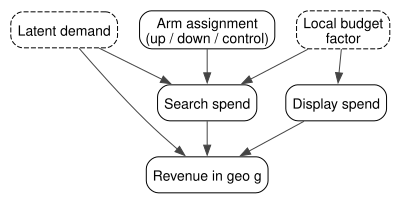

In [2]:
dag = Digraph("calibration_dgp")
dag.attr(rankdir="TB", bgcolor="white", nodesep="0.3", ranksep="0.5", pad="0.15")
dag.attr("node", shape="box", style="rounded", fontname="Helvetica", fontsize="14")
dag.attr("edge", color="#444444", fontname="Helvetica", fontsize="11")
dag.node("assignment", "Arm assignment\n(up / down / control)")
dag.node("budget", "Local budget\nfactor", style="rounded,dashed")
dag.node("demand", "Latent demand", style="rounded,dashed")
dag.node("search", "Search spend")
dag.node("display", "Display spend")
dag.node("revenue", "Revenue in geo g")
dag.edge("assignment", "search")
dag.edge("budget", "search")
dag.edge("budget", "display")
dag.edge("demand", "search")
dag.edge("demand", "revenue")
dag.edge("search", "revenue")
dag.edge("display", "revenue")
display(SVG(dag.pipe(format="svg")))

**Caption:** Causal structure for simulated geo-level revenue, conditional on geo-specific baseline budgets, baseline revenue, response parameters, and observed seasonality. Dashed nodes are unobserved demand and local budget drivers. Independent spend and observation noise are omitted.

Demand affects search budgets and revenue. Local budgets drive both channels. These processes continue throughout the example. During the experiment, randomized arm assignment adds a signed increment to ordinary search budgets; it does not alter demand, display budgets, or revenue response parameters. This is an intervention on the spend increment, rather than replacement of the entire search-budget rule. Selected controls receive no increment and supply the donor pool; up/down doses are randomized among the remaining geos.

We illustrate the workflow for a synthetic retailer operating in **48 geographic markets, labeled with the contiguous US states**. Sixteen markets increase search spend, sixteen decrease it, and sixteen act as controls. There are two steps: **synthetic controls** estimate experimental geo-level effects with CausalPy, then a **hierarchical geo MMM** uses those estimates for calibration. We compare MMMs fitted with and without calibration and check their response curves and marginal ROAS against known truth. Both estimate a shared weekly revenue baseline without observing the true demand index. These are two stages of one workflow.

We keep the simulated business deliberately simple so we can focus on setting up the geo test, estimating lift, and passing those estimates into MMM calibration. The two channels have stable response curves and no carryover; the same budget process runs before and during the experiment, with only the assigned search increment changing.

The labels use [Census state codes](https://cdn.www.census.gov/library/reference/code-lists/ansi/ansi-codes-for-states.html). Market sizes, assignments, spend, response parameters, and revenue are all simulated; the state names do not imply realistic state populations or market economics. These are state-level markets, not DMAs.

| Arm | Markets | Planned search change per market | Delivered change | Expected effect |
|---|---:|---:|---:|---|
| Up | 16 | +8,000 USD/week | +7,200 USD/week | Positive |
| Down | 16 | −8,000 USD/week | −7,200 USD/week | Negative |
| Control | 16 | 0 | 0 | Zero |

Equal delivered increases and decreases make this example **spend-neutral**. They need not make it revenue-neutral: different markets can have different responses to the same change in spend. We will inspect both the individual effects used for calibration and their net revenue effect.

This extends {ref}`mmm_geolift_calibration` and assumes familiarity with {ref}`mmm_multidimensional_example` and [CausalPy's up/down/control example](https://causalpy.readthedocs.io/en/latest/notebooks/up-down-control-geolift-pymc.html). We use a supplied assignment to focus on estimation and calibration; selecting or optimizing real experiment markets is outside this walkthrough.

## Setup and data-generating process

The data-generating process is a teaching example, rather than a realistic retailer simulator. We use just two channels, **search and display**, with geo-specific logistic response curves, shared seasonality, and no carryover.

A shared, unobserved **demand index** raises ordinary search budgets and revenue directly. Display has budget variation independent of demand, while a geo-specific weekly local budget factor still correlates the channels. The fitted MMMs do not receive this simulated demand index. Instead, they estimate a shared weekly non-media revenue baseline from the observed data. Its role is to represent common demand changes without forcing the media response curves to explain them. Because demand also drives search spending, baseline and media attribution can still trade off; experimental calibration supplies additional information about search response.


The equation below defines the **simulation truth** used to generate revenue, including latent demand $D_t$. For geo $g$ and week $t$,

$$
\begin{aligned}
Y_{gt} &= a_g+\sum_c f_{gc}(X_{gtc})+s_t+10{,}000 D_t+\epsilon_{gt},\\
f_{gc}(x) &= 100{,}000\beta_{gc}\tanh\!\left(\frac{\lambda_{gc}x}{2\times100{,}000}\right).
\end{aligned}
$$

The sum runs over search and display; $a_g$ is baseline revenue in USD/week. Here $D_t$ is a smooth, standardized common demand index, $s_t$ is shared annual seasonality, and observation noise has SD 1,000 USD/week. Search budgets increase with demand; display budget variation is independent of demand, and both channels share geo-specific weekly budget shocks. These budget shocks and spend noise are independent across weeks; common demand is persistent.

There are **two periods: 136 pre-intervention weeks and an eight-week intervention**. The ordinary demand, budget, seasonality, and noise processes continue through both. During the last eight weeks, up/down geos receive an additional signed search budget; display and control-market budgets follow their original paths. We retain the ordinary budget plan before adding the experiment dose, so the calibration inputs include the weekly planned and delivered spend paths.

Both fitted MMMs use spend, seasonality, and a **latent shared weekly revenue baseline**. They never receive the true $D_t$ values. The baseline has one unknown additive contribution per pre-intervention week, shared across all 48 geos, with a Normal prior of scale 15,000 USD/week, constrained to sum to zero so geo intercepts carry the overall level. This is a time-varying baseline, rather than a third period or a known demand control. Search calibration helps distinguish media response from that baseline; it still does not guarantee recovery of either channel. In practice, credible observed demand controls should also be considered.

Both MMMs and CausalPy use **all 136 pre-intervention weeks**. Reusing those outcomes makes the two-stage estimates dependent; the marginal calibration likelihood does not model that dependence. Intervention outcomes enter the MMM only through experimental effect summaries. Weekly budgets vary, so calibration compares the **average of the weekly response differences**, rather than evaluating a nonlinear curve at mean spend.

In [3]:
geos = (
    "AL AZ AR CA CO CT DE FL GA ID IL IN IA KS KY LA ME MD MA MI MN MS MO MT "
    "NE NV NH NJ NM NY NC ND OH OK OR PA RI SC SD TN TX UT VT VA WA WV WI WY"
).split()
geos = sorted(geos)
G = len(geos)
# Select an illustrative donor pool before randomizing the active doses.
donor_geos = geos[::3]
dates = pd.date_range("2022-01-03", periods=144, freq="W-MON")
train_dates = dates[:136]
estimation_dates = dates
experiment_start, experiment_end = dates[136], dates[-1]
is_intervention = dates >= experiment_start
window = dates[is_intervention]
true_lam = rng_parameters.lognormal(np.log([4.0, 3.0]), 0.12, (G, 2))
true_beta = rng_parameters.lognormal(np.log([0.6, 0.5]), 0.12, (G, 2))
true_intercept = rng_parameters.uniform(0.50, 0.70, G)
true_intercept[[geos.index(g) for g in donor_geos]] = np.linspace(
    0.20, 1.00, len(donor_geos)
)
base_spend = rng_spend.uniform(32_000, 48_000, (G, 2))
# Market properties are fixed before treatment assignment. Controls are selected,
# not randomized; only the 32 experimental markets receive randomized up/down doses.
experimental_geos = [g for g in geos if g not in donor_geos]
assigned = rng_assignment.permutation(experimental_geos).tolist()
arm_size = len(geos) // 3
arms = {
    "up": sorted(assigned[:arm_size]),
    "down": sorted(assigned[arm_size:]),
    "control": donor_geos,
}
geo_arm = {g: arm for arm, members in arms.items() for g in members}


# Smooth, shared latent demand drives search budgets and non-media revenue.
# Fitted MMMs estimate a shared baseline without observing this index.
def smooth_process(shape, persistence=0.85):
    values = rng_spend.normal(size=shape)
    for t in range(1, shape[0]):
        values[t] = (
            persistence * values[t - 1] + np.sqrt(1 - persistence**2) * values[t]
        )
    return (values - values.mean(axis=0)) / values.std(axis=0)


latent_demand = smooth_process((144,))
local_budget = rng_spend.normal(size=(len(dates), G, 1))
baseline = base_spend[None, :, :] * (
    1 + latent_demand[:, None, None] * np.array([0.18, 0.0]) + 0.08 * local_budget
) + rng_spend.normal(0, 1_500, (len(dates), G, 2))
historical_spend = baseline[~is_intervention]
DEMAND_EFFECT = 10_000.0  # Direct revenue change (USD/week) per SD of demand.
planned = baseline.copy()
for arm, sign in [("up", 1), ("down", -1)]:
    planned[np.ix_(is_intervention, [geos.index(g) for g in arms[arm]], [0])] += (
        sign * 8_000
    )
realized = baseline + 0.9 * (planned - baseline)
season_controls = np.column_stack(
    [np.sin(2 * np.pi * np.arange(144) / 52), np.cos(2 * np.pi * np.arange(144) / 52)]
)
true_gamma = np.array([0.06, 0.03])


def media_response(spend):
    x = ptx.as_xtensor(spend / SCALE, dims=("time", "geo", "channel"))
    lam = ptx.as_xtensor(true_lam, dims=("geo", "channel"))
    saturated = (
        logistic_saturation(x, lam=lam).transpose("time", "geo", "channel").eval()
    )
    return (true_beta * saturated).sum(axis=-1) * SCALE


non_media = (
    SCALE * (true_intercept + season_controls @ true_gamma[:, None])
    + DEMAND_EFFECT * latent_demand[:, None]
)
mu_baseline = non_media + media_response(baseline)
mu_experiment = non_media + media_response(realized)
mu_history = mu_baseline[~is_intervention]
y_history = mu_history + rng_history.normal(0, 1_000, mu_history.shape)
y_experiment = mu_experiment[is_intervention] + rng_experiment.normal(
    0, 1_000, (is_intervention.sum(), G)
)
true_lift = pd.Series(
    (mu_experiment - mu_baseline)[is_intervention].mean(axis=0), index=geos
)
truth = {
    "saturation_lam": true_lam,
    "saturation_beta": true_beta,
    "baseline_revenue": SCALE * true_intercept,  # USD/week
    "demand_effect": DEMAND_EFFECT,  # USD/week per SD of demand
    "mean_search_lift": true_lift,  # USD/week
}

In [4]:
def long_features(spend, selected_dates, controls):
    frame = pd.DataFrame(spend.reshape(-1, 2), columns=channels)
    frame["baseline_input"] = 1.0
    frame["date"] = np.repeat(selected_dates, G)
    frame["geo"] = np.tile(geos, len(selected_dates))
    frame[["annual_sin", "annual_cos"]] = np.repeat(controls, G, axis=0)
    return frame


# Both stages use the same 136 pre-intervention weeks.
training_spend = realized[~is_intervention]
X_train = long_features(training_spend, train_dates, season_controls[:136])
y_train = pd.Series(y_history.ravel(), name="revenue")
experiment_revenue = pd.DataFrame(
    np.vstack([y_history, y_experiment]), index=dates, columns=geos
)
spend_columns = pd.MultiIndex.from_product([geos, channels], names=["geo", "channel"])
spend_baseline = pd.DataFrame(
    baseline.reshape(len(dates), -1), index=dates, columns=spend_columns
)
spend_realized = pd.DataFrame(
    realized.reshape(len(dates), -1), index=dates, columns=spend_columns
)
for frame in (experiment_revenue, spend_baseline, spend_realized):
    frame.attrs["unit"] = "USD/week"
np.testing.assert_equal(len(set(geos)), 48)
np.testing.assert_equal([len(arms[a]) for a in arms], [16, 16, 16])
np.testing.assert_equal(len(train_dates.intersection(estimation_dates)), 136)
if train_dates.max() >= experiment_start:
    raise ValueError("MMM target dates must precede the intervention.")
np.testing.assert_array_equal(realized[:, :, 1], baseline[:, :, 1])
np.testing.assert_array_equal(
    realized[:, [geos.index(g) for g in arms["control"]]],
    baseline[:, [geos.index(g) for g in arms["control"]]],
)
for values in (historical_spend, baseline, realized, y_history, y_experiment):
    if not np.isfinite(values).all() or values.min() <= 0:
        raise ValueError("The simulation must have finite positive spend and revenue.")


def as_mmm_data(features, target):
    return to_mmm_dataset(
        features,
        target,
        date_column="date",
        dims=("geo",),
        channel_columns=channels,
        control_columns=["annual_sin", "annual_cos"],
        extra_vars=["baseline_input"],
        target_column="revenue",
    )


mmm_training_data = as_mmm_data(X_train, y_train)

Selecting and assigning geos to arms is an important part of designing a credible geo test, but it is a topic of its own and outside this walkthrough's focus on estimation and calibration. Here we select an illustrative donor pool with deliberately broad baseline revenues, then randomize the remaining 32 markets between up and down doses. Controls are selected, not randomized, and all market properties are fixed before active-dose assignment. This makes donor support plausible; we still check the pre-intervention fit below.

To compare trajectories across markets of different sizes, we **rebase each geo's revenue to 100 at its last pre-intervention week**. We divide every weekly revenue value by that geo's observed revenue in the reference week and multiply by 100. The lower panel then averages those geo-level indices within each arm, giving every market equal weight.

This normalization is **only a data transformation for visual inspection**. It is not a usable analytical or causal result: a single reference week is noisy, and rescaling neither estimates a counterfactual nor adjusts for confounding or different trends. The raw revenue and spend data used for synthetic control and MMM fitting remain unchanged. Step 1 will estimate the experimental effects.

In [5]:
from plotly.subplots import make_subplots

observed_revenue = pd.DataFrame(
    np.vstack([y_history, y_experiment]), index=dates, columns=geos
)
normalization_date = dates[dates < experiment_start][-1]
last_pre_revenue = observed_revenue.loc[normalization_date]
revenue_index = observed_revenue.div(last_pre_revenue, axis="columns") * 100
geo_figure = make_subplots(
    rows=2,
    cols=1,
    shared_xaxes=True,
    vertical_spacing=0.16,
    subplot_titles=("Indexed revenue by market", "Mean revenue index in each arm"),
)
geo_figure.update_annotations(x=0, xanchor="left", font={"size": 14})
for arm, members in arms.items():
    for i, geo in enumerate(members):
        geo_figure.add_trace(
            go.Scatter(
                x=dates,
                y=revenue_index[geo],
                mode="lines",
                line={"color": ARM_COLORS[arm], "width": 2},
                opacity=0.8,
                name=f"{arm.title()} ({len(members)} markets)",
                legendgroup=arm,
                showlegend=i == 0,
                meta=[geo, arm],
                hovertemplate=(
                    "<b>%{meta[0]}</b> · %{meta[1]} arm"
                    "<br>Week: %{x|%d %b %Y}"
                    "<br>Revenue index: %{y:.1f} (last pre = 100)<extra></extra>"
                ),
            ),
            row=1,
            col=1,
        )
    geo_figure.add_trace(
        go.Scatter(
            x=dates,
            y=revenue_index[members].mean(axis=1),
            mode="lines",
            line={"color": ARM_COLORS[arm], "width": 3},
            name=f"{arm.title()} mean",
            legendgroup=arm,
            showlegend=False,
            meta=[arm, len(members)],
            hovertemplate=(
                "<b>%{meta[0]} arm mean</b> · %{meta[1]} markets"
                "<br>Week: %{x|%d %b %Y}"
                "<br>Mean revenue index: %{y:.1f} (last pre = 100)<extra></extra>"
            ),
        ),
        row=2,
        col=1,
    )
geo_figure.add_vline(
    x=experiment_start.to_pydatetime(), line_dash="dash", line_color="black"
)
geo_figure.add_annotation(
    x=experiment_start,
    y=1.045,
    yref="paper",
    text="Intervention",
    showarrow=False,
    xanchor="right",
)
geo_figure.add_hline(y=100, line_dash="dot", line_color="#b3b3b3")
geo_figure.update_layout(
    template="plotly_white",
    autosize=True,
    height=int(FIG_HEIGHT * 100 * 2.3),
    margin={"l": 85, "r": 20, "t": 110, "b": 55},
    font={"size": 13},
    hovermode="closest",
    hoverlabel={"bgcolor": "white", "font": {"color": "#222222"}},
    legend={"orientation": "h", "y": 1.14, "x": 0},
)
geo_figure.update_xaxes(tickformat="%b %Y", nticks=6)
geo_figure.update_xaxes(title_text="Week", row=2, col=1)
geo_figure.update_yaxes(tickformat=".0f")
geo_figure.update_yaxes(
    title_text="Revenue index<br>(last pre-intervention = 100)", row=1, col=1
)
geo_figure.update_yaxes(
    title_text="Mean revenue index<br>(last pre-intervention = 100)", row=2, col=1
)
display(
    HTML(
        geo_figure.to_html(
            full_html=False,
            include_plotlyjs="cdn",
            config={"responsive": True, "displaylogo": False},
            post_script="""
        const plot = document.getElementById('{plot_id}');
        let previousWidth = 0;
        const observer = new ResizeObserver(([entry]) => {
            const width = entry.contentRect.width;
            if (width > 0 && width !== previousWidth) {
                previousWidth = width;
                Plotly.Plots.resize(plot);
            }
        });
        observer.observe(plot.parentElement);
        """,
        )
    )
)

**Caption:** Revenue indices by market (top) and their arithmetic means within each arm (bottom), colored by up, down, and control arm. Every market equals 100 at the last pre-intervention week; the horizontal dotted reference marks that value. The panels share the time axis and use separate index ranges. Hover identifies the market or arm, week, and index. Black dashed lines mark intervention. The same ordinary budget process runs throughout; only the assigned search increment starts at the line. Both stages use all pre-intervention weeks.

The indices make changes from a common reference easier to see despite different starting revenue levels. Separation between arm means remains descriptive; it is not estimated lift.

In [6]:
historical_correlations = (
    X_train.groupby("geo")[channels].corr().loc[(slice(None), "search"), "display"]
)
display(historical_correlations.describe().to_frame("Historical channel correlation"))

,Historical channel correlation
count,48.000000
mean,0.355479
std,0.072008
min,0.211000
25%,0.299072
50%,0.370256
75%,0.408463
max,0.493746


The variable-budget history contains correlated channels because they share local budget changes. Search also tracks latent demand; display does not. The association is partly noncausal: demand also raises revenue without passing through media. The next section creates spend changes by assignment instead of following demand; unchanged markets retain the common demand signal used to estimate untreated revenue.

### A spend-neutral intervention

Equal planned increases and decreases receive the same 90% delivery fraction. We verify neutrality from the delivered panel rather than assuming planned spend was delivered. Each geo retains its own baseline and signed change.

,planned,delivered
up,"$128,000","$115,200"
down,"$-128,000","$-115,200"
control,$0,$0
net,$0,$0


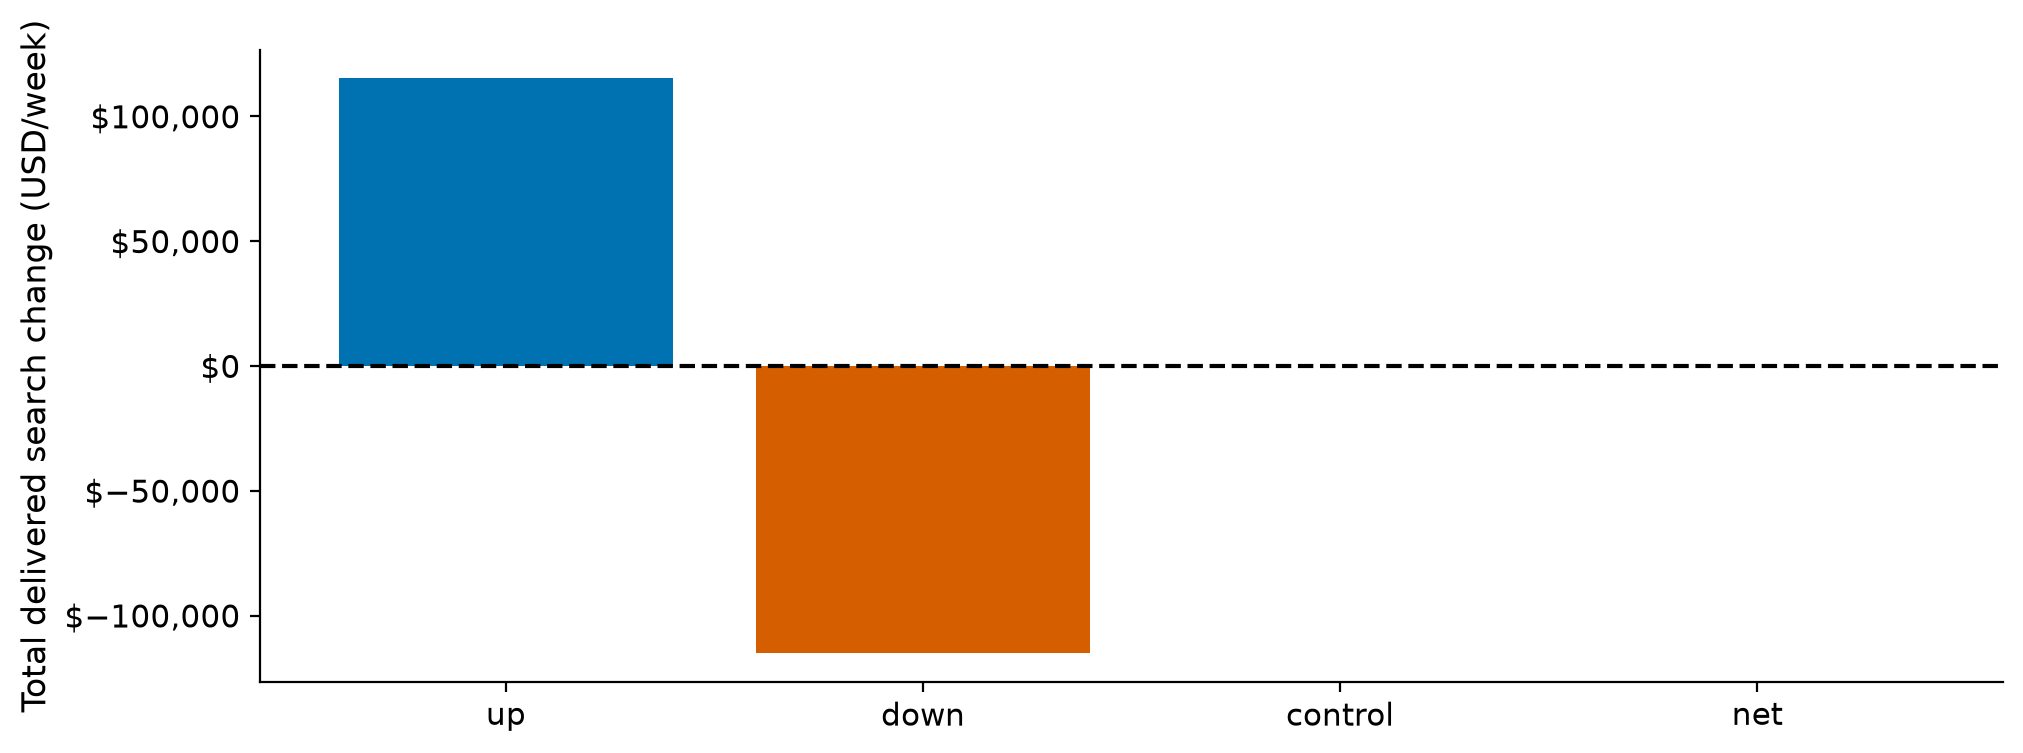

In [7]:
accounting = pd.DataFrame(index=["up", "down", "control"])
for label, panel in [("planned", planned), ("delivered", realized)]:
    accounting[label] = [
        (panel - baseline)[is_intervention][:, [geos.index(g) for g in arms[a]], 0]
        .sum(axis=1)
        .mean()
        for a in accounting.index
    ]
accounting.loc["net"] = accounting.sum()
for panel in (planned, realized):
    np.testing.assert_allclose(
        (panel - baseline)[is_intervention, :, 0].sum(axis=1), 0, atol=1e-8
    )
np.testing.assert_equal((baseline[~is_intervention].std(axis=0) > 0).all(), True)
np.testing.assert_equal((baseline[is_intervention].std(axis=0) > 0).all(), True)
np.testing.assert_allclose(
    np.ptp((realized - baseline)[is_intervention], axis=0), 0, atol=1e-8
)
# Choose all example markets from baseline spend, before estimating any effects.
ranked_geos = {
    arm: sorted(members, key=lambda g: base_spend[geos.index(g), 0])
    for arm, members in arms.items()
}
representatives = {arm: members[arm_size // 2] for arm, members in ranked_geos.items()}
example_ranks = np.linspace(0, arm_size - 1, 4, dtype=int).tolist()
curve_examples = [
    (arm, ranked_geos[arm][rank]) for arm in arms for rank in example_ranks
]
return_examples = [
    (arm, ranked_geos[arm][rank]) for rank in example_ranks for arm in ("up", "down")
]
display_example_ranks = np.linspace(0, arm_size - 1, 3, dtype=int).tolist()
display_ranked_geos = {
    arm: sorted(members, key=lambda g: base_spend[geos.index(g), 1])
    for arm, members in arms.items()
}
display_examples = [
    (arm, display_ranked_geos[arm][rank])
    for arm in arms
    for rank in display_example_ranks
]
display(accounting.style.format("${:,.0f}"))
fig, ax = plt.subplots(figsize=(FIG_WIDTH, FIG_HEIGHT))
ax.bar(
    accounting.index,
    accounting.delivered,
    color=[COLOR_UP, COLOR_DOWN, COLOR_CONTROL, "black"],
)
ax.axhline(0, color="black", linestyle="--")
ax.set_ylabel("Total delivered search change (USD/week)")
ax.yaxis.set_major_formatter(USD)
plt.show()

**Caption:** Delivered weekly search changes summed across markets in each arm and across the experiment. The planned increases and decreases offset, and the delivered changes leave total search spend unchanged.

Spend neutrality does not imply outcome neutrality: a dollar added in one geo need not generate as much revenue as a dollar removed elsewhere would lose. Geos have different response curves and baseline spend, so their marginal returns differ; diminishing returns also make equal increases and decreases asymmetric. Market size can contribute in practice, but baseline revenue alone cancels from this simulation's additive lift contrast. Representative markets below are selected by median baseline search spend before inspecting estimated effects.

## Step 1: estimate experimental lift with synthetic controls

CausalPy constructs each treated market's missing **no-intervention revenue path** as a weighted combination of control markets. Donor weights are learned from all 136 pre-intervention weeks, then applied during the eight-week intervention. Observed revenue minus that counterfactual is signed impact. One joint fit estimates all treated markets; neither active arm supplies donors to the other.

Controls receive no experimental increment, but their ordinary budgets and revenue continue to vary. Donor combinations can reflect shared demand and seasonality; geo-specific budget variation and nonlinear responses make the counterfactual an approximation. Identification requires stable relationships, adequate pre-period fit, no spillovers, and no concurrent market-specific changes correlated with assignment. Randomizing active doses alone does not verify those assumptions. We use two chains with 2,000 retained draws each and hide sampling progress.

For effect uncertainty, we use the fitted model's **posterior-predictive revenue draws**. These include residual outcome variation as well as uncertainty in donor weights. CausalPy's default impact summaries use conditional-mean predictions, which can be too narrow for these varying weekly budgets. The predictive extension still assumes the fitted residual model transfers to the experiment; it does not make a biased counterfactual valid.

In [8]:
sc_fit_kwargs = dict(
    tune=2_000,
    draws=2_000,
    chains=2,
    cores=2,
    target_accept=0.95,
    nuts_sampler="nutpie",
    random_seed=SEED + 10,
    progressbar=False,
)
mmm_fit_kwargs = dict(
    tune=3_000,
    draws=3_000,
    chains=2,
    cores=2,
    nuts_sampler="nutpie",
    random_seed=SEED + 20,
    progressbar=False,
    nuts={
        "target_accept": 0.99,
        "adaptation": "low_rank",
        "mass_matrix_eigval_cutoff": 3,
    },
)
result = cp.UpDownGeoLift(
    experiment_revenue,
    treatment_time=experiment_start,
    arms=arms,
    model=cp.pymc_models.SoftmaxWeightedSumFitter(sample_kwargs=sc_fit_kwargs),
).fit()

# Use predictive outcomes, not only uncertainty in the fitted conditional mean.
pre_counterfactual = result.model.predict(
    result.pre_design["control"]
).posterior_predictive["y_hat"]
post_counterfactual = result.model.predict(
    result.post_design["control"]
).posterior_predictive["y_hat"]
pre_impact = result.pre_design["treated"] - pre_counterfactual
post_impact = result.post_design["treated"] - post_counterfactual

In [9]:
# Average each joint impact draw over the same eight experiment weeks.
mean_effect_draws = post_impact.sel(obs_ind=window).mean("obs_ind")
calibration_geos = mean_effect_draws.treated_units.values.tolist()
search_baseline = spend_baseline.loc[window, [(g, "search") for g in calibration_geos]]
search_delivered = spend_realized.loc[window, [(g, "search") for g in calibration_geos]]
lift_rows = pd.DataFrame(
    {
        "geo": calibration_geos,
        "arm": [geo_arm[g] for g in calibration_geos],
        "channel": "search",
        "x": search_baseline.mean().to_numpy(),
        "delta_x": (search_delivered - search_baseline).mean().to_numpy(),
        "delta_y": mean_effect_draws.mean(["chain", "draw"]).to_numpy(),
        "sigma": mean_effect_draws.std(["chain", "draw"]).to_numpy(),
        "window_start": experiment_start,
        "window_end": experiment_end,
        "n_periods": len(window),
        "spend_unit": "USD/week",
        "outcome_unit": "USD/week",
    }
)
np.testing.assert_equal(len(lift_rows), 32)
np.testing.assert_equal(set(lift_rows.geo), set(arms["up"] + arms["down"]))
np.testing.assert_equal(np.isfinite(lift_rows[["delta_y", "sigma"]]).all().all(), True)
np.testing.assert_equal((lift_rows.sigma > 0).all(), True)
display(
    lift_rows[["geo", "arm", "channel", "x", "delta_x", "delta_y", "sigma"]]
    .groupby("arm", sort=False)
    .head(2)
    .style.format({c: "{:,.1f}" for c in ["x", "delta_x", "delta_y", "sigma"]})
)

,geo,arm,channel,x,delta_x,delta_y,sigma
0,AZ,up,search,"52,866.3","7,200.0","4,249.4","1,417.9"
1,CT,up,search,"43,651.8","7,200.0","3,924.3","1,576.5"
16,AR,down,search,"43,619.9","-7,200.0","-5,384.5","1,503.3"
17,CO,down,search,"37,128.6","-7,200.0","-6,542.4","1,568.1"


The summaries below describe the same inclusive weekly window. Confirm that spend and outcome units match before attaching their associated weekly paths and mean effects to an MMM.

In [10]:
display(
    lift_rows[
        ["window_start", "window_end", "n_periods", "spend_unit", "outcome_unit"]
    ].drop_duplicates()
)

,window_start,window_end,n_periods,spend_unit,outcome_unit
0,2024-08-12,2024-09-30,8,USD/week,USD/week


These are fitted estimates, not true effects. `x` and `delta_x` summarize weekly business-as-usual spend and its delivered increment for display in this table. The calibration calculation below retains the **full weekly spend paths**; it does not substitute these means into a nonlinear response curve. `delta_y` is the posterior mean of mean weekly impact, and `sigma` is the SD of that time-averaged predictive impact: do not divide it by √8 again. All four quantities are in USD/week.

The scalar `to_mmm_lift` exporter requires stable baseline spend within its window. We therefore summarize the predictive impact draws directly and attach an exact period-average contrast in Step 2. We retain all 32 signed estimates without flipping, clipping, or dropping noisy effects.

In [11]:
pre_residual = result.result.impact_pre
pre_rmse = np.sqrt((pre_residual.mean(["chain", "draw"]) ** 2).mean("obs_ind"))
pre_table = pre_rmse.to_series().rename("Pre-fit RMSE (USD/week)").to_frame()
pre_table["arm"] = [geo_arm[g] for g in pre_table.index]
pre_table = pre_table.sort_values(["arm", "Pre-fit RMSE (USD/week)"])
display(
    HTML(
        '<details class="admonition note">'
        "<summary><strong>Optional diagnostic: pre-intervention donor fit</strong></summary>"
        "<p>RMSE summarizes the pre-intervention residuals for every treated market, in USD/week. "
        "A poor fit is a reason to investigate the donor model. A good in-sample fit does not "
        "establish that post-intervention counterfactual assumptions hold.</p>"
        + pre_table.style.format({"Pre-fit RMSE (USD/week)": "${:,.0f}"}).to_html()
        + "</details>"
    )
)

,Pre-fit RMSE (USD/week),arm
treated_units,,
MD,"$3,559",down
FL,"$3,847",down
MN,"$3,932",down
OH,"$3,977",down
MT,"$3,980",down
AR,"$4,010",down
OR,"$4,064",down
MA,"$4,099",down
GA,"$4,110",down


The optional diagnostic above checks pre-intervention fit for every treated market. The next figure shows observed outcomes, estimated counterfactuals, and signed impacts for the two predetermined representative markets.

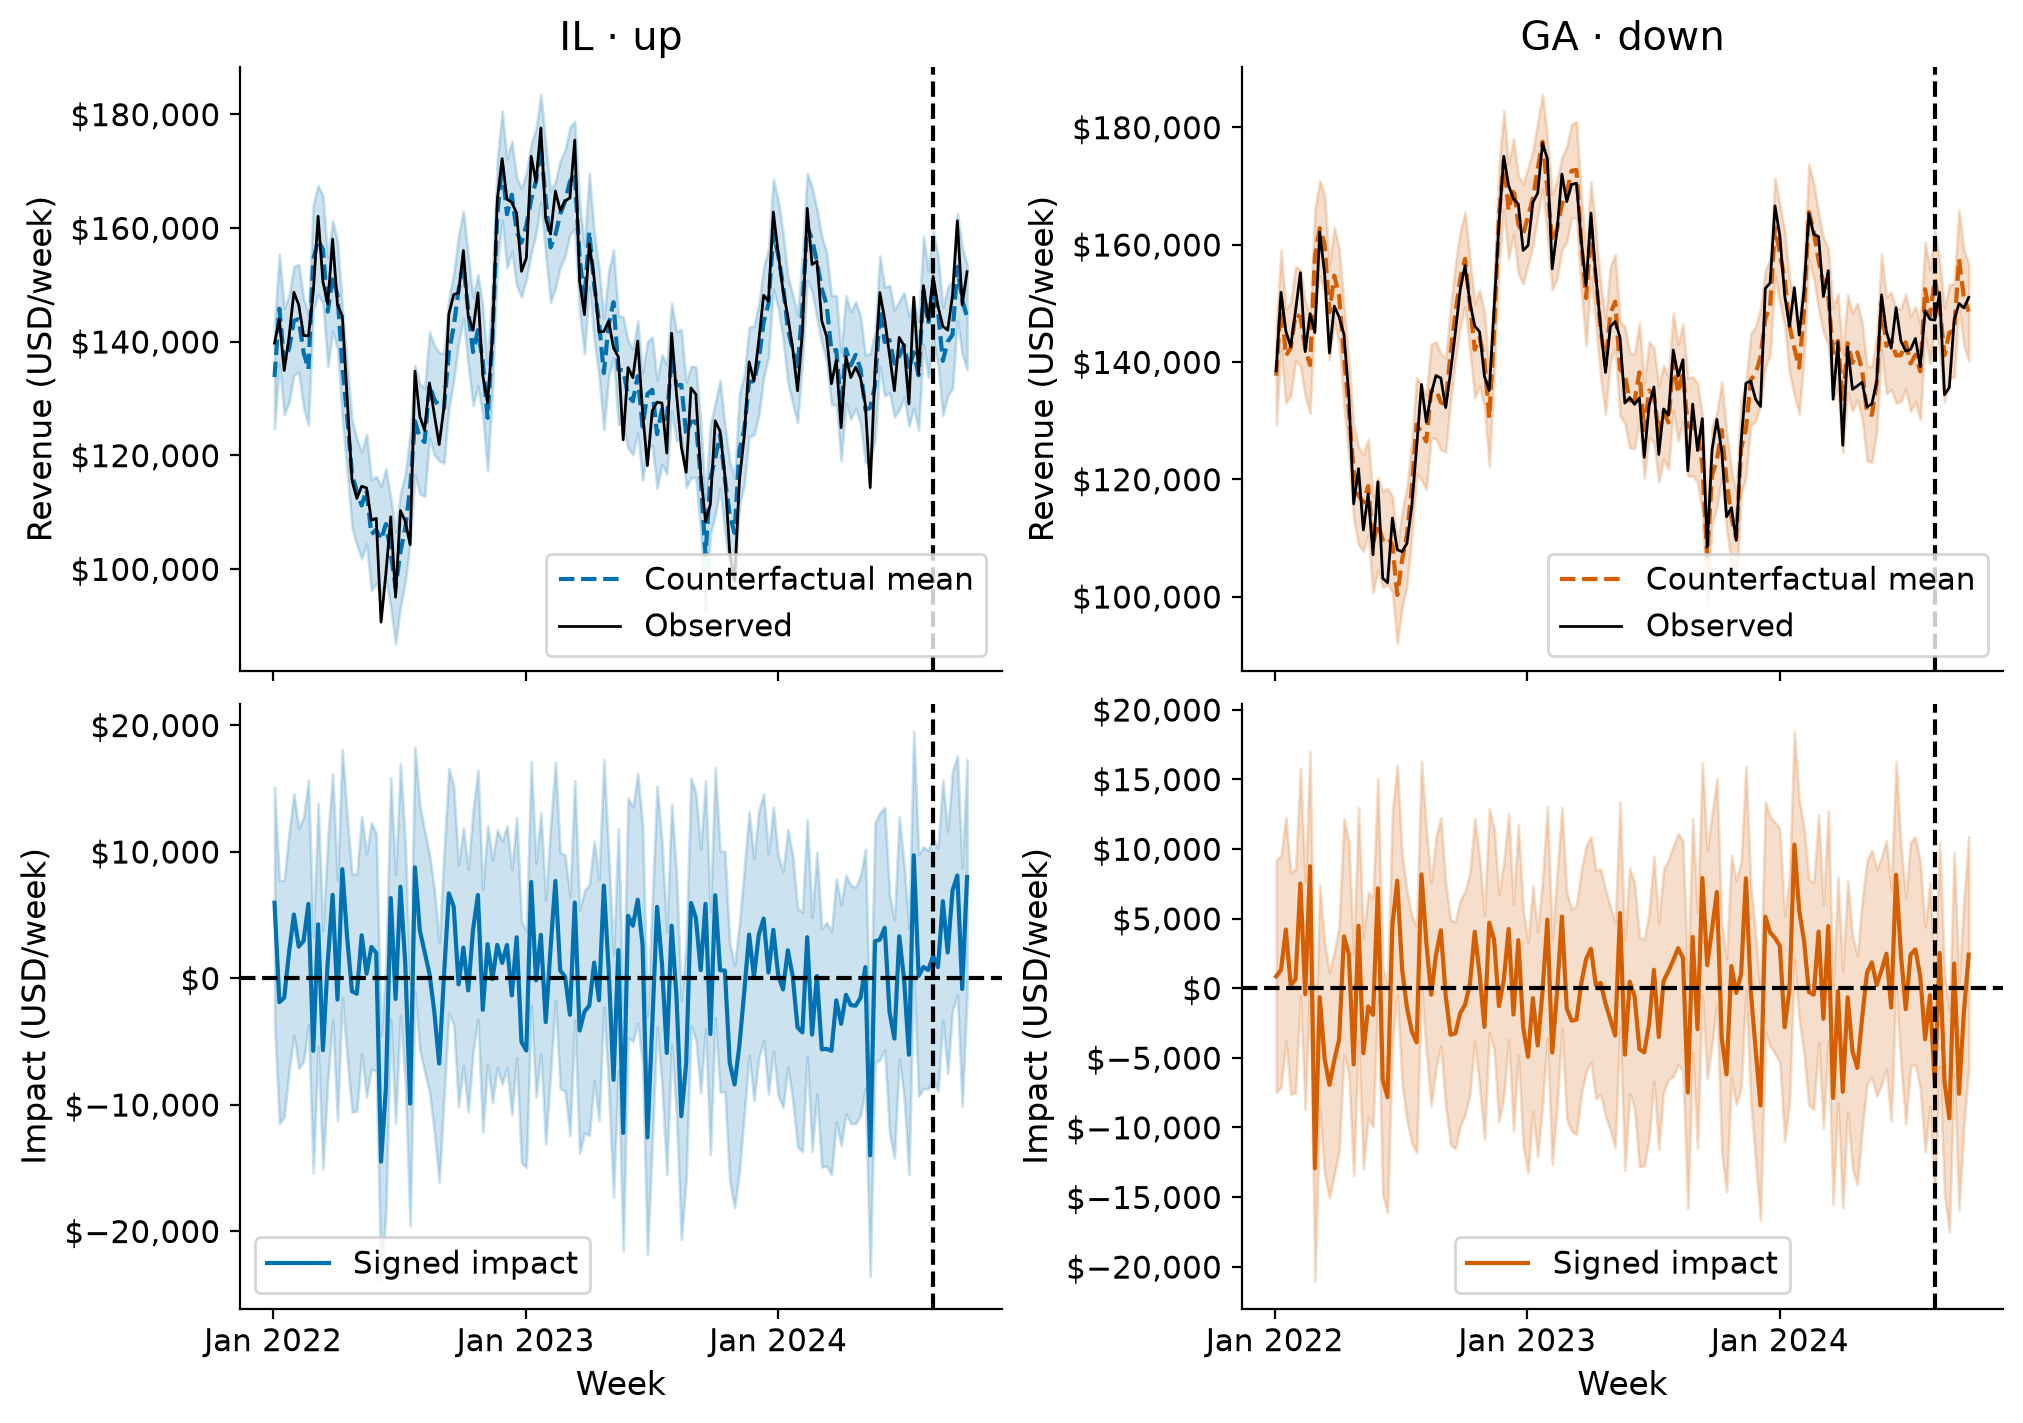

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(FIG_WIDTH, FIG_HEIGHT * 2), sharex=True)
for col, arm in enumerate(["up", "down"]):
    g = representatives[arm]
    color = ARM_COLORS[arm]
    pre = pre_impact.sel(treated_units=g)
    post = post_impact.sel(treated_units=g)
    impacts = xr.concat([pre, post], dim="obs_ind").transpose(
        "chain", "draw", "obs_ind"
    )
    observed = experiment_revenue[g]
    cf = (
        xr.DataArray(
            observed.to_numpy(), dims="obs_ind", coords={"obs_ind": observed.index}
        )
        - impacts
    )
    for row, draws, label in [
        (0, cf, "Counterfactual mean"),
        (1, impacts, "Signed impact"),
    ]:
        ax = axes[row, col]
        bounds = draws.quantile([0.03, 0.97], dim=["chain", "draw"])
        ax.fill_between(
            estimation_dates,
            bounds.isel(quantile=0),
            bounds.isel(quantile=1),
            color=color,
            alpha=0.2,
        )
        ax.plot(
            estimation_dates,
            draws.mean(["chain", "draw"]),
            color=color,
            linestyle="--" if row == 0 else "-",
            label=label,
        )
        ax.axvline(experiment_start, color="black", linestyle="--")
        ax.yaxis.set_major_formatter(USD)
        ax.set_ylabel("Revenue (USD/week)" if row == 0 else "Impact (USD/week)")
        ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=3, maxticks=4))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
        ax.legend(fontsize=11)
    axes[0, col].plot(
        estimation_dates, observed, color="black", linewidth=1, label="Observed"
    )
    axes[0, col].set_title(f"{g} · {arm}")
    axes[0, col].legend(fontsize=11)
    axes[1, col].axhline(0, color="black", linestyle="--")
    axes[1, col].set_xlabel("Week")
plt.show()

**Caption:** Observed revenue, synthetic counterfactual, and signed weekly impact for median-baseline-spend up/down geos. Bands are 94% equal-tailed posterior-predictive intervals (ETIs); the vertical dashed line marks intervention. These impact intervals condition on observed donor outcomes.

**Stakeholder question: How much weekly revenue did the search intervention add or remove in each treated geo?**

The next plot compares CausalPy's posterior estimates of each geo's eight-week mean effect with the known true effects, so we can inspect signs, magnitudes, and uncertainty.

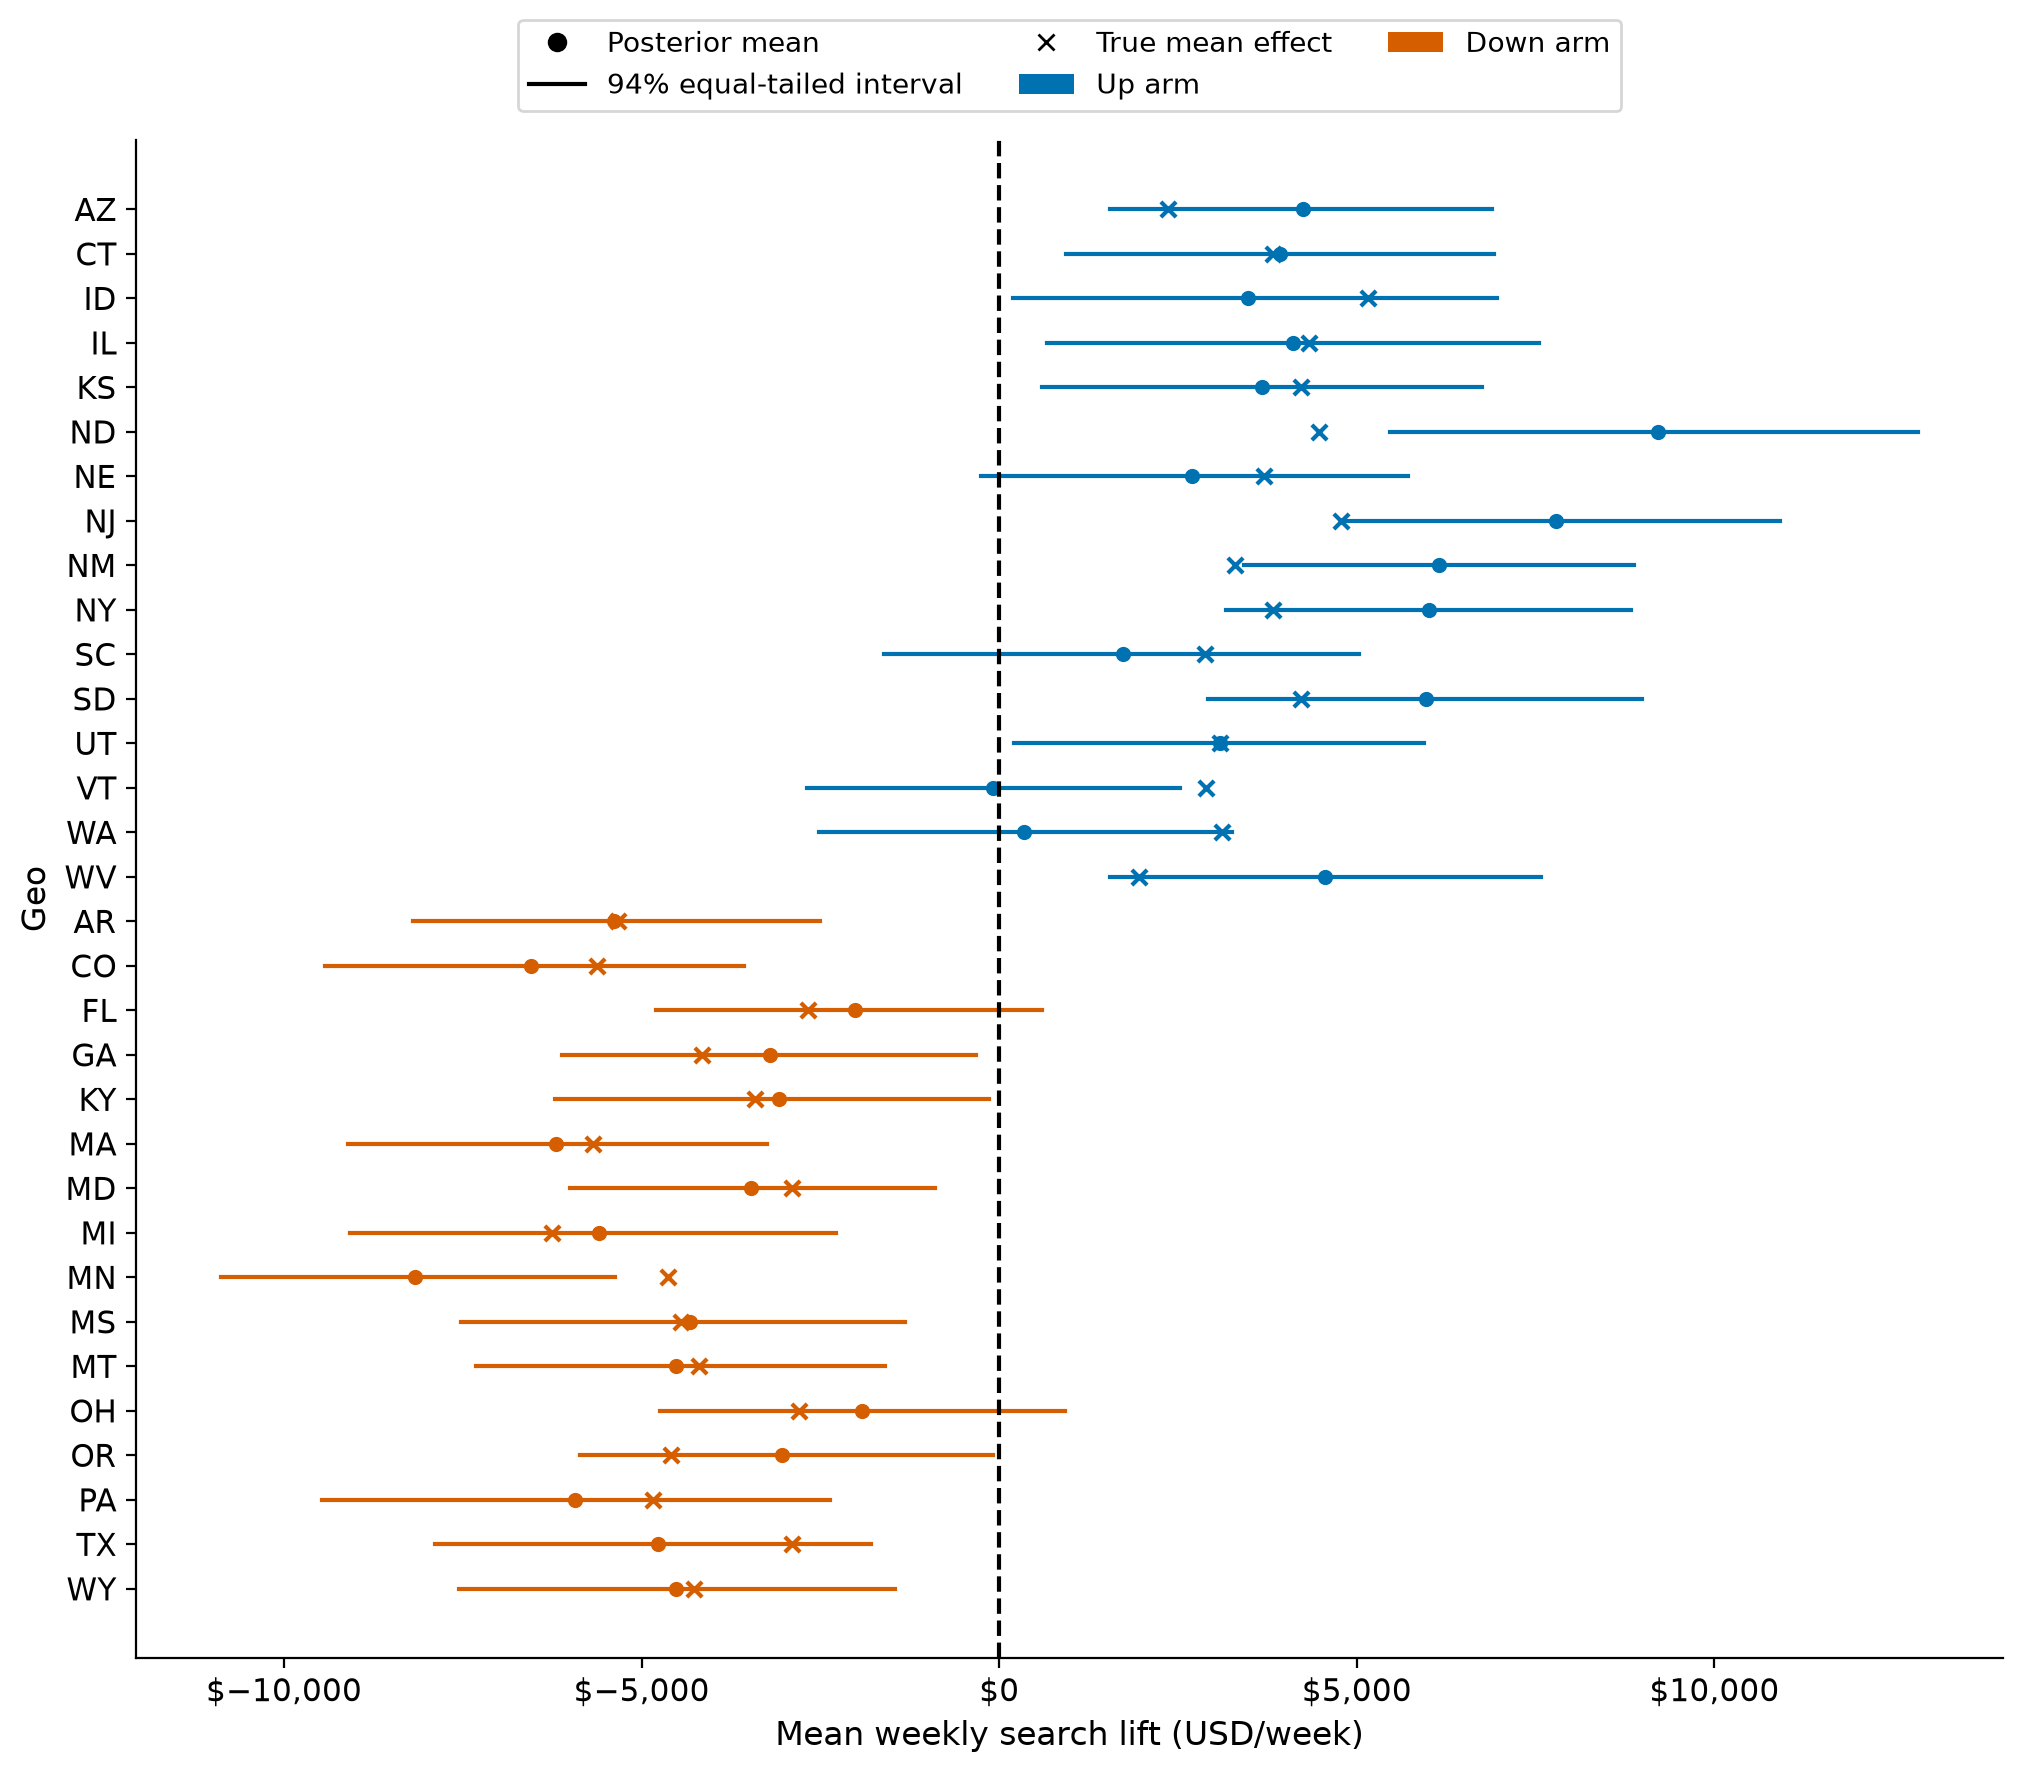

In [13]:
geo_effects = lift_rows.set_index("geo")[["arm"]].copy()
geo_effects["mean"] = mean_effect_draws.mean(["chain", "draw"]).to_numpy()
geo_effects["lower_94"] = mean_effect_draws.quantile(
    0.03, dim=["chain", "draw"]
).to_numpy()
geo_effects["upper_94"] = mean_effect_draws.quantile(
    0.97, dim=["chain", "draw"]
).to_numpy()
geo_effects["truth"] = true_lift.reindex(geo_effects.index)
geo_effects["covered"] = (geo_effects.truth >= geo_effects.lower_94) & (
    geo_effects.truth <= geo_effects.upper_94
)
fig, ax = plt.subplots(figsize=(FIG_WIDTH, FIG_HEIGHT * 2.5))
for i, (_g, row) in enumerate(geo_effects.iterrows()):
    color = ARM_COLORS[row.arm]
    ax.plot([row.lower_94, row.upper_94], [i, i], color=color)
    ax.scatter(row["mean"], i, color=color, s=20)
    ax.scatter(row.truth, i, color=color, marker="x", s=30)
ax.legend(
    handles=[
        Line2D(
            [], [], marker="o", linestyle="none", color="black", label="Posterior mean"
        ),
        Line2D([], [], color="black", label="94% equal-tailed interval"),
        Line2D(
            [],
            [],
            marker="x",
            linestyle="none",
            color="black",
            label="True mean effect",
        ),
        Patch(facecolor=COLOR_UP, label="Up arm"),
        Patch(facecolor=COLOR_DOWN, label="Down arm"),
    ],
    loc="lower center",
    bbox_to_anchor=(0.5, 1.01),
    ncol=3,
    fontsize=10,
)
ax.set_yticks(range(len(geo_effects)), geo_effects.index)
ax.invert_yaxis()
ax.axvline(0, color="black", linestyle="--")
ax.xaxis.set_major_formatter(USD)
ax.set_xlabel("Mean weekly search lift (USD/week)")
ax.set_ylabel("Geo")
plt.show()

**Caption:** Mean weekly search effect estimates (dots), 94% equal-tailed intervals from posterior-predictive counterfactual draws (segments), and known simulation effects (crosses). Blue and orange identify up and down arms. Predictive intervals include fitted residual revenue variation as well as donor-weight uncertainty; they remain conditional on the counterfactual model and its transfer assumptions.

In [14]:
print(
    f"True effects inside 94% predictive intervals: {geo_effects.covered.sum()}/{len(geo_effects)}"
)

True effects inside 94% predictive intervals: 27/32


### Does spend neutrality imply revenue neutrality?

The budget accounting showed no net change in search spend. To assess the revenue consequence, sum the geo-level effects within each arm and across both active arms. These are **total effects across markets, in USD/week**, averaged over the same eight weeks. Controls contribute zero intervention effect in this simulation. The summaries below are for interpretation; they are not extra calibration observations.

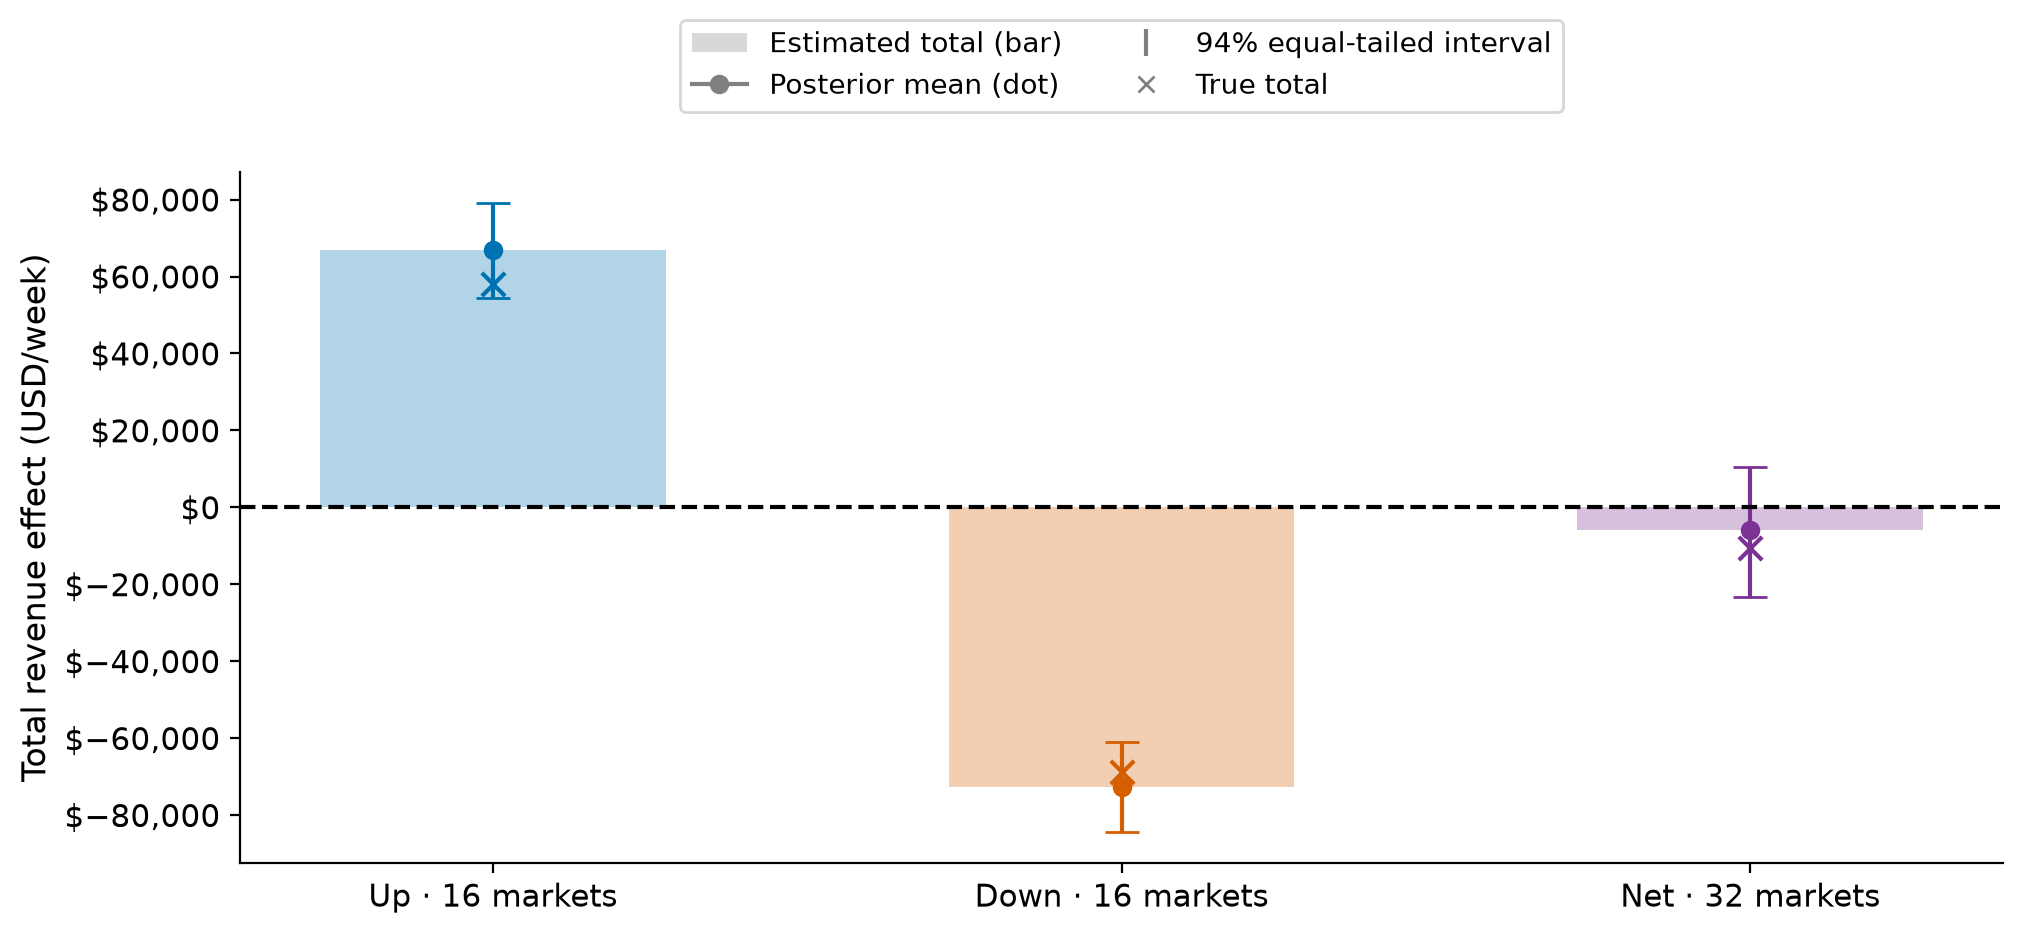

In [15]:
effect_draws = mean_effect_draws.sel(treated_units=lift_rows.geo.tolist())
# Sum corresponding joint draws, retaining the dependence represented by the fit.
arm_totals = [
    effect_draws.sel(treated_units=arms[arm]).sum("treated_units")
    for arm in ["up", "down"]
]
revenue_totals = xr.concat(
    [*arm_totals, effect_draws.sum("treated_units")],
    dim=pd.Index(["up", "down", "net"], name="summary"),
)
true_totals = [true_lift.loc[arms[arm]].sum() for arm in ["up", "down"]]
true_totals.append(true_lift.loc[arms["up"] + arms["down"]].sum())
means = revenue_totals.mean(["chain", "draw"])
intervals = revenue_totals.quantile([0.03, 0.97], dim=["chain", "draw"])
fig, ax = plt.subplots(figsize=(FIG_WIDTH, FIG_HEIGHT * 1.3))
for i, (label, color, expected_total) in enumerate(
    zip(
        ["up", "down", "net"],
        [COLOR_UP, COLOR_DOWN, COLOR_NET],
        true_totals,
        strict=True,
    )
):
    mean = float(means.sel(summary=label))
    lower, upper = intervals.sel(summary=label).values
    ax.bar(i, mean, color=color, alpha=0.3, width=0.55)
    ax.errorbar(
        i, mean, yerr=[[mean - lower], [upper - mean]], fmt="o", color=color, capsize=6
    )
    ax.scatter(i, expected_total, marker="x", color=color, s=70, zorder=4)
ax.legend(
    handles=[
        Patch(facecolor="gray", alpha=0.3, label="Estimated total (bar)"),
        Line2D([], [], marker="o", color="gray", label="Posterior mean (dot)"),
        ax.errorbar(
            [],
            [],
            yerr=[],
            fmt="none",
            color="gray",
            capsize=6,
            label="94% equal-tailed interval",
        ),
        Line2D([], [], marker="x", linestyle="none", color="gray", label="True total"),
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, 1.24),
    ncol=2,
    fontsize=10,
)
ax.set_xticks(range(3), ["Up · 16 markets", "Down · 16 markets", "Net · 32 markets"])
ax.axhline(0, color="black", linestyle="--")
ax.yaxis.set_major_formatter(USD)
ax.set_ylabel("Total revenue effect (USD/week)")
plt.show()

**Caption:** Mean total weekly revenue effects (bars/dots), 94% equal-tailed intervals (whiskers), and true totals (crosses), for each active arm and their net effect. Totals sum aligned geo-level predictive effect draws before computing intervals, retaining the dependence available in those draws. Counterfactual model limitations still apply.

The known response curves determine whether up-market gains offset down-market losses. Equal spend changes do not force them to match. More deliberate market assignment or dose choices could target revenue neutrality, but would require pre-experiment response information, credible counterfactuals, and statistical power. We do not optimize that allocation here.

Step 1 gives us a signed search effect and its uncertainty for each treated geo. Step 2 will compare those estimates with the average weekly differences implied by the MMM. We pass the geo labels, full baseline/delivered spend paths, effect summaries, and matching weekly window together. For the simpler constant-spend calibration case, see {ref}`mmm_geolift_calibration`.

## Step 2: calibrate a hierarchical geo MMM

Both fits use all **136 pre-intervention weeks**. Every geo/channel has its own free saturation amplitude (`beta`) and curvature (`lam`). **Both parameters are partially pooled across all geos within each channel**: their log values share population means and spreads that are learned from the data. Neither parameter is fixed to simulation truth. The prior centers express channel-level knowledge; their uncertainty and the geo-level variation are estimated. We do not fit separate arm models: arm labels describe the experiment, not the MMM dimensions.

This sharing lets treated geos influence control-geo estimates indirectly, including their curvature. It does not force curves to move together or guarantee improvement in an untested geo or channel. Controls retain their own historical likelihoods and receive no direct search lift observation.

The **uncalibrated** fit uses the ordinary revenue likelihood. The **calibrated** fit additionally receives one mean experimental search effect per treated geo, aligned with its eight weekly spend contrasts. Priors, training data, scaling, and sampler settings are otherwise identical. Both estimate the same shared weekly baseline without observing demand. The baseline captures common revenue variation; the experiment helps separate search response from that variation. A free geo-level residual scale handles remaining unexplained variation. The experimental constraints, priors, and pooling jointly determine recovery; one average contrast cannot identify every geo's full two-parameter response curve by itself.

### Define the shared model

Response-parameter tradeoffs can slow MCMC. Both MMMs use [Nutpie low-rank adaptation](https://pymc-devs.github.io/nutpie/sampling-options.html), 3,000 tuning and 3,000 retained draws per chain, and target acceptance 0.99. These settings address sampling geometry, not confounding. Check parameter, population, and response-quantity diagnostics before interpreting recovery.

In [16]:
def make_mmm():
    saturation_priors = {
        "lam": Prior(
            "Normal",
            transform="exp",
            mu=Prior(
                "Normal",
                mu=xr.DataArray(
                    np.log([4.0, 3.0]), dims="channel", coords={"channel": channels}
                ),
                sigma=0.5,
                dims="channel",
            ),
            sigma=Prior("HalfNormal", sigma=0.3, dims="channel"),
            dims=("geo", "channel"),
            centered=False,
        ),
        "beta": Prior(
            "Normal",
            transform="exp",
            mu=Prior(
                "Normal",
                mu=xr.DataArray(
                    np.log([0.6, 0.5]), dims="channel", coords={"channel": channels}
                ),
                sigma=0.5,
                dims="channel",
            ),
            sigma=Prior("HalfNormal", sigma=0.3, dims="channel"),
            dims=("geo", "channel"),
            centered=False,
        ),
    }
    mmm = MMM(
        date_column="date",
        target_column="revenue",
        channel_columns=channels,
        dims=("geo",),
        control_columns=["annual_sin", "annual_cos"],
        adstock=NoAdstock(l_max=1),
        saturation=LogisticSaturation(priors=saturation_priors),
        scaling=Scaling(
            channel=FixedScaling(dims=(), value=SCALE),
            target=FixedScaling(dims=(), value=SCALE),
        ),
        model_config={
            "intercept": Prior("Normal", mu=0.6, sigma=0.4, dims="geo"),
            "gamma_control": Prior("Normal", mu=0, sigma=0.1, dims="control"),
            "likelihood": Prior(
                "Normal", sigma=Prior("HalfNormal", sigma=0.15, dims="geo")
            ),
        },
    )
    # One latent weekly effect is shared by all geos (0.15 scaled = USD 15,000).
    # The input is constant; no simulated demand values enter the fitted model.
    mmm.add_mu_effect(
        ControlMuEffect(
            data_vars=["baseline_input"],
            prefix="weekly_baseline",
            prior=Prior("ZeroSumNormal", sigma=0.15, dims="date", core_dims="date"),
        )
    )
    return mmm

In [17]:
# Verify the media response and outcome scales independently of omitted demand.
truth_mmm = make_mmm()
X_baseline = long_features(baseline, estimation_dates, season_controls)
X_realized = long_features(realized, estimation_dates, season_controls)
truth_predictions = []
for features in (X_baseline, X_realized):
    truth_mmm.build_model(as_mmm_data(features, pd.Series(np.ones(len(features)))))
    fixed = pm.do(
        truth_mmm.model,
        {
            "saturation_lam": true_lam,
            "saturation_beta": true_beta,
            "intercept_contribution": true_intercept,
            "gamma_control": true_gamma,
            "weekly_baseline_baseline_input_coef": (
                DEMAND_EFFECT * latent_demand / SCALE
            ),
        },
    )
    truth_predictions.append(
        pm.draw(fixed["mu"].transpose("date", "geo"), random_seed=SEED) * SCALE
    )
np.testing.assert_allclose(truth_predictions[0], mu_baseline, rtol=1e-10)
np.testing.assert_allclose(truth_predictions[1], mu_experiment, rtol=1e-10)
np.testing.assert_allclose(
    (truth_predictions[1] - truth_predictions[0])[is_intervention].mean(axis=0),
    true_lift,
    atol=1e-8,
)
del truth_mmm
print("Fixed-truth media response and shared baseline reproduce the simulator.")

Fixed-truth media response and shared baseline reproduce the simulator.


The numerical check sets all response parameters and the latent baseline to their known simulation values solely to verify the response function, outcome scale, and signed eight-week contrast. Both fitted MMMs instead infer those quantities; neither receives the true demand index. The constant `baseline_input` column only makes a shared date-level effect available to the model.

In [18]:
mmm_uncalibrated = make_mmm()
mmm_uncalibrated.build_model(mmm_training_data)
idata_uncalibrated = mmm_uncalibrated.fit(X_train, y_train, **mmm_fit_kwargs)

Rewrite failure due to: local_convert_negative_indices


node: Subtensor{i}(Second.0, -1)


TRACEBACK:


Traceback (most recent call last):
  File "/Users/benjamv/.codex/worktrees/multi-arm-geolift-calibration/pymc-marketing/.scratch/venv313/lib/python3.13/site-packages/pytensor/graph/rewriting/basic.py", line 1960, in process_node
    replacements = node_rewriter.transform(
        fgraph, node, enforce_tracks=enforce_tracks
    )
  File "/Users/benjamv/.codex/worktrees/multi-arm-geolift-calibration/pymc-marketing/.scratch/venv313/lib/python3.13/site-packages/pytensor/graph/rewriting/basic.py", line 1026, in transform
    return self.fn(fgraph, node)
           ~~~~~~~^^^^^^^^^^^^^^
  File "/Users/benjamv/.codex/worktrees/multi-arm-geolift-calibration/pymc-marketing/.scratch/venv313/lib/python3.13/site-packages/pytensor/tensor/rewriting/subtensor.py", line 1418, in local_convert_negative_indices
    new_val = val + dim_length
              ~~~~^~~~~~~~~~~~
OverflowError: Python integer 136 out of bounds for int8



Rewrite failure due to: local_convert_negative_indices


...

node: Subtensor{i}(Second.0, -1)


TRACEBACK:


Traceback (most recent call last):
  File "/Users/benjamv/.codex/worktrees/multi-arm-geolift-calibration/pymc-marketing/.scratch/venv313/lib/python3.13/site-packages/pytensor/graph/rewriting/basic.py", line 1960, in process_node
    replacements = node_rewriter.transform(
        fgraph, node, enforce_tracks=enforce_tracks
    )
  File "/Users/benjamv/.codex/worktrees/multi-arm-geolift-calibration/pymc-marketing/.scratch/venv313/lib/python3.13/site-packages/pytensor/graph/rewriting/basic.py", line 1026, in transform
    return self.fn(fgraph, node)
           ~~~~~~~^^^^^^^^^^^^^^
  File "/Users/benjamv/.codex/worktrees/multi-arm-geolift-calibration/pymc-marketing/.scratch/venv313/lib/python3.13/site-packages/pytensor/tensor/rewriting/subtensor.py", line 1418, in local_convert_negative_indices
    new_val = val + dim_length
              ~~~~^~~~~~~~~~~~
OverflowError: Python integer 136 out of bounds for int8



Output()

/Users/benjamv/.codex/worktrees/multi-arm-geolift-calibration/pymc-marketing/.scratch/venv313/lib/python3.13/site-packages/pymc/sampling/deterministic.py:143: FutureWarning: `merge_dataset` is deprecated and will be removed in a future release. Use `extend_dataset=True` to add the deterministics to the original dataset, passing a `.copy()` of it if it should not be mutated.


### Fit the calibrated model

Start a fresh model with the same specification. For each geo and posterior parameter draw, evaluate search response at each week's baseline and delivered spend, take the eight differences, and average them. That average is compared with CausalPy's mean weekly effect and its posterior SD.

The usual `add_lift_test_measurements` call compares one fixed spend pair. Our budgets vary, so the short PyMC helper below attaches the period-average contrast directly. It uses the MMM's saturation function and free parameters, with USD values divided by the same fixed scale used by both models. It supplies **32 observations, not 256 independent weekly observations**.

We pass marginal means and SDs rather than the full joint impact posterior. Inspect dependence and shape before attaching them:

In [19]:
effect_matrix = (
    effect_draws.stack(sample=("chain", "draw"))
    .transpose("treated_units", "sample")
    .values
)
effect_correlations = np.corrcoef(effect_matrix)
off_diagonal = effect_correlations[np.triu_indices(len(lift_rows), 1)]
effect_skewness = pd.DataFrame(effect_matrix.T).skew()
display(
    pd.Series(
        {
            "Median absolute off-diagonal correlation": np.median(np.abs(off_diagonal)),
            "Maximum absolute off-diagonal correlation": np.max(np.abs(off_diagonal)),
            "Maximum absolute marginal skewness": np.abs(effect_skewness).max(),
        }
    )
)

Median absolute off-diagonal correlation     0.011128
Maximum absolute off-diagonal correlation    0.049419
Maximum absolute marginal skewness           0.140767
dtype: float64

Using one Normal calibration observation per geo retains the marginal means and standard deviations but discards cross-geo covariance and non-Gaussian shape. This is a **two-stage summary approximation**. Small sampled correlations do not establish independence of real-world uncertainty: shared donor shocks and counterfactual-model error may still matter. Strong dependence or skew requires investigation before claiming precision; a covariance-aware extension is outside this example.

In [20]:
def add_period_average_lift(mmm, effects, baseline_panel, delivered_panel):
    geo_positions = {g: i for i, g in enumerate(mmm.model.coords["geo"])}
    search_position = list(mmm.model.coords["channel"]).index("search")
    columns = [(g, "search") for g in effects.geo]
    before = baseline_panel.loc[window, columns].to_numpy().T / SCALE
    after = delivered_panel.loc[window, columns].to_numpy().T / SCALE
    indices = ptx.as_xtensor(
        [geo_positions[g] for g in effects.geo], dims=("lift_geo",)
    )
    with mmm.model:
        mmm.model.add_coord("lift_geo", effects.geo.to_list())
        mmm.model.add_coord("lift_week", window.to_list())
        lam = mmm.model["saturation_lam"].isel(geo=indices, channel=search_position)
        beta = mmm.model["saturation_beta"].isel(geo=indices, channel=search_position)
        before = ptx.as_xtensor(before, dims=("lift_geo", "lift_week"))
        after = ptx.as_xtensor(after, dims=("lift_geo", "lift_week"))
        weekly_lift = mmm.saturation.function(
            after, lam, beta
        ) - mmm.saturation.function(before, lam, beta)
        mean_lift = pmd.Deterministic(
            "multi_arm_geo_lift_model_estimated_lift", weekly_lift.mean(dim="lift_week")
        )
        pmd.Deterministic(
            "multi_arm_geo_lift_model_estimated_lift_original_scale", mean_lift * SCALE
        )
        pmd.Normal(
            "multi_arm_geo_lift",
            mu=mean_lift,
            sigma=ptx.as_xtensor(effects.sigma.to_numpy() / SCALE, dims=("lift_geo",)),
            observed=ptx.as_xtensor(
                effects.delta_y.to_numpy() / SCALE, dims=("lift_geo",)
            ),
        )


mmm_calibrated = make_mmm()
mmm_calibrated.build_model(mmm_training_data)
add_period_average_lift(mmm_calibrated, lift_rows, spend_baseline, spend_realized)
np.testing.assert_equal(mmm_calibrated.model["multi_arm_geo_lift"].eval().size, 32)
idata_calibrated = mmm_calibrated.fit(X_train, y_train, **mmm_fit_kwargs)

Rewrite failure due to: local_convert_negative_indices


node: Subtensor{i}(Second.0, -1)


TRACEBACK:


Traceback (most recent call last):
  File "/Users/benjamv/.codex/worktrees/multi-arm-geolift-calibration/pymc-marketing/.scratch/venv313/lib/python3.13/site-packages/pytensor/graph/rewriting/basic.py", line 1960, in process_node
    replacements = node_rewriter.transform(
        fgraph, node, enforce_tracks=enforce_tracks
    )
  File "/Users/benjamv/.codex/worktrees/multi-arm-geolift-calibration/pymc-marketing/.scratch/venv313/lib/python3.13/site-packages/pytensor/graph/rewriting/basic.py", line 1026, in transform
    return self.fn(fgraph, node)
           ~~~~~~~^^^^^^^^^^^^^^
  File "/Users/benjamv/.codex/worktrees/multi-arm-geolift-calibration/pymc-marketing/.scratch/venv313/lib/python3.13/site-packages/pytensor/tensor/rewriting/subtensor.py", line 1418, in local_convert_negative_indices
    new_val = val + dim_length
              ~~~~^~~~~~~~~~~~
OverflowError: Python integer 136 out of bounds for int8



Rewrite failure due to: local_convert_negative_indices


...

node: Subtensor{i}(Second.0, -1)


TRACEBACK:


Traceback (most recent call last):
  File "/Users/benjamv/.codex/worktrees/multi-arm-geolift-calibration/pymc-marketing/.scratch/venv313/lib/python3.13/site-packages/pytensor/graph/rewriting/basic.py", line 1960, in process_node
    replacements = node_rewriter.transform(
        fgraph, node, enforce_tracks=enforce_tracks
    )
  File "/Users/benjamv/.codex/worktrees/multi-arm-geolift-calibration/pymc-marketing/.scratch/venv313/lib/python3.13/site-packages/pytensor/graph/rewriting/basic.py", line 1026, in transform
    return self.fn(fgraph, node)
           ~~~~~~~^^^^^^^^^^^^^^
  File "/Users/benjamv/.codex/worktrees/multi-arm-geolift-calibration/pymc-marketing/.scratch/venv313/lib/python3.13/site-packages/pytensor/tensor/rewriting/subtensor.py", line 1418, in local_convert_negative_indices
    new_val = val + dim_length
              ~~~~^~~~~~~~~~~~
OverflowError: Python integer 136 out of bounds for int8



Output()

/Users/benjamv/.codex/worktrees/multi-arm-geolift-calibration/pymc-marketing/.scratch/venv313/lib/python3.13/site-packages/pymc/sampling/deterministic.py:143: FutureWarning: `merge_dataset` is deprecated and will be removed in a future release. Use `extend_dataset=True` to add the deterministics to the original dataset, passing a `.copy()` of it if it should not be mutated.


Build once, attach calibration, then fit; rebuilding would discard the additional graph. The signed Normal observations preserve up and down directions. Arm labels, units, and windows are provenance; named geo coordinates select each response curve.

Keep the weekly baseline/delivered panels and effect table alongside the fitted draws. This notebook-level temporal likelihood is not automatically reconstructed by `MMM.load`; rebuilding it requires the same helper and aligned panels. For a fixed spend pair, use the standard `add_lift_test_measurements` API instead.

The canonical dataset retains the constant baseline input in addition to the standard channel/control blocks. We build each graph from that dataset before calling `fit` with the matching pre-intervention frame and target. To reconstruct this example, repeat that construction and reattach the period-average calibration helper; automatic loading alone does not recreate this custom setup.

In [21]:
def diagnostic_row(label, draws, sample_stats=None, quantity="All reported parameters"):
    rhat = az.rhat(draws).to_array().values
    ess = az.ess(draws).to_array().values
    return {
        "fit": label,
        "quantity": quantity,
        "divergences": (
            int(sample_stats.diverging.sum()) if sample_stats is not None else np.nan
        ),
        "max_rhat": float(np.nanmax(rhat)),
        "min_ess": float(np.nanmin(ess)),
    }


diag = [
    diagnostic_row(
        "CausalPy",
        result.model.idata.posterior.to_dataset(),
        result.model.idata.sample_stats,
        "Model parameters",
    ),
    diagnostic_row(
        "CausalPy",
        effect_draws.to_dataset(name="effect"),
        quantity="Mean effects",
    ),
]
for label, idata in [
    ("Uncalibrated MMM", idata_uncalibrated),
    ("Calibrated MMM", idata_calibrated),
]:
    diag.append(
        diagnostic_row(
            label,
            xr.Dataset(
                {
                    var: idata.posterior[var]
                    for var in [
                        "saturation_lam",
                        "saturation_beta",
                        "saturation_lam_raw_mu",
                        "saturation_lam_raw_sigma",
                        "saturation_beta_raw_mu",
                        "saturation_beta_raw_sigma",
                        "gamma_control",
                        "intercept_contribution",
                        "weekly_baseline_baseline_input_coef",
                    ]
                }
            ),
            idata.sample_stats,
        )
    )
    for var, quantity in [
        ("saturation_lam_raw_sigma", "Log-curvature spread"),
        ("saturation_beta_raw_sigma", "Log-amplitude spread"),
    ]:
        diag.append(
            diagnostic_row(
                label, idata.posterior[var].to_dataset(name=var), quantity=quantity
            )
        )
display(
    pd.DataFrame(diag)
    .set_index(["fit", "quantity"])
    .style.format(
        {"divergences": "{:,.0f}", "max_rhat": "{:.4f}", "min_ess": "{:,.0f}"},
        na_rep="—",
    )
)

Inspect divergences, R-hat, and effective sample size before interpreting the comparisons. Targets are zero divergences, R-hat ≤ 1.01, and approximately 400 effective draws for central quantities. Each row summarizes the worst R-hat and ESS across its parameters or channels. Divergences describe the whole fit; dashes avoid repeating those counts for subsets or derived quantities. These diagnostics assess sampling, not the validity of the counterfactual or pooling assumptions.

The response curves meet the reported sampling targets below, but not every model parameter does. In particular, the population spread of log-curvature mixes more slowly; the log-amplitude spread also needs attention where ESS is below target. The following comparisons concern response quantities. This run does **not** support precise conclusions about between-geo curvature heterogeneity. Longer sampling and renewed diagnostic checks are needed before interpreting population spreads.

### Reality check: search contributions across spend levels

**Stakeholder question: Have we recovered how much revenue search contributes across spend levels, for up, down, and control geos?**

Compare each MMM's search saturation curves with the known simulation truth. Both fits use the same historical outcomes and priors; the calibrated fit additionally receives the experimental search constraints. Better agreement with the experimental contrasts need not recover absolute channel contributions, so we assess the full curves separately from local returns.

The columns are **up, down, and control arms**. Each column shows four example geos, selected at evenly spaced ranks from lowest to highest baseline search spend before inspecting estimated effects. Controls have no direct lift observations; their curves can still shift through partial pooling and redistribution of attribution, and improvement is not guaranteed. The table below assesses search recovery across all geos. Changes in the untested display channel appear in a separate supporting section after the marginal-ROAS analysis.

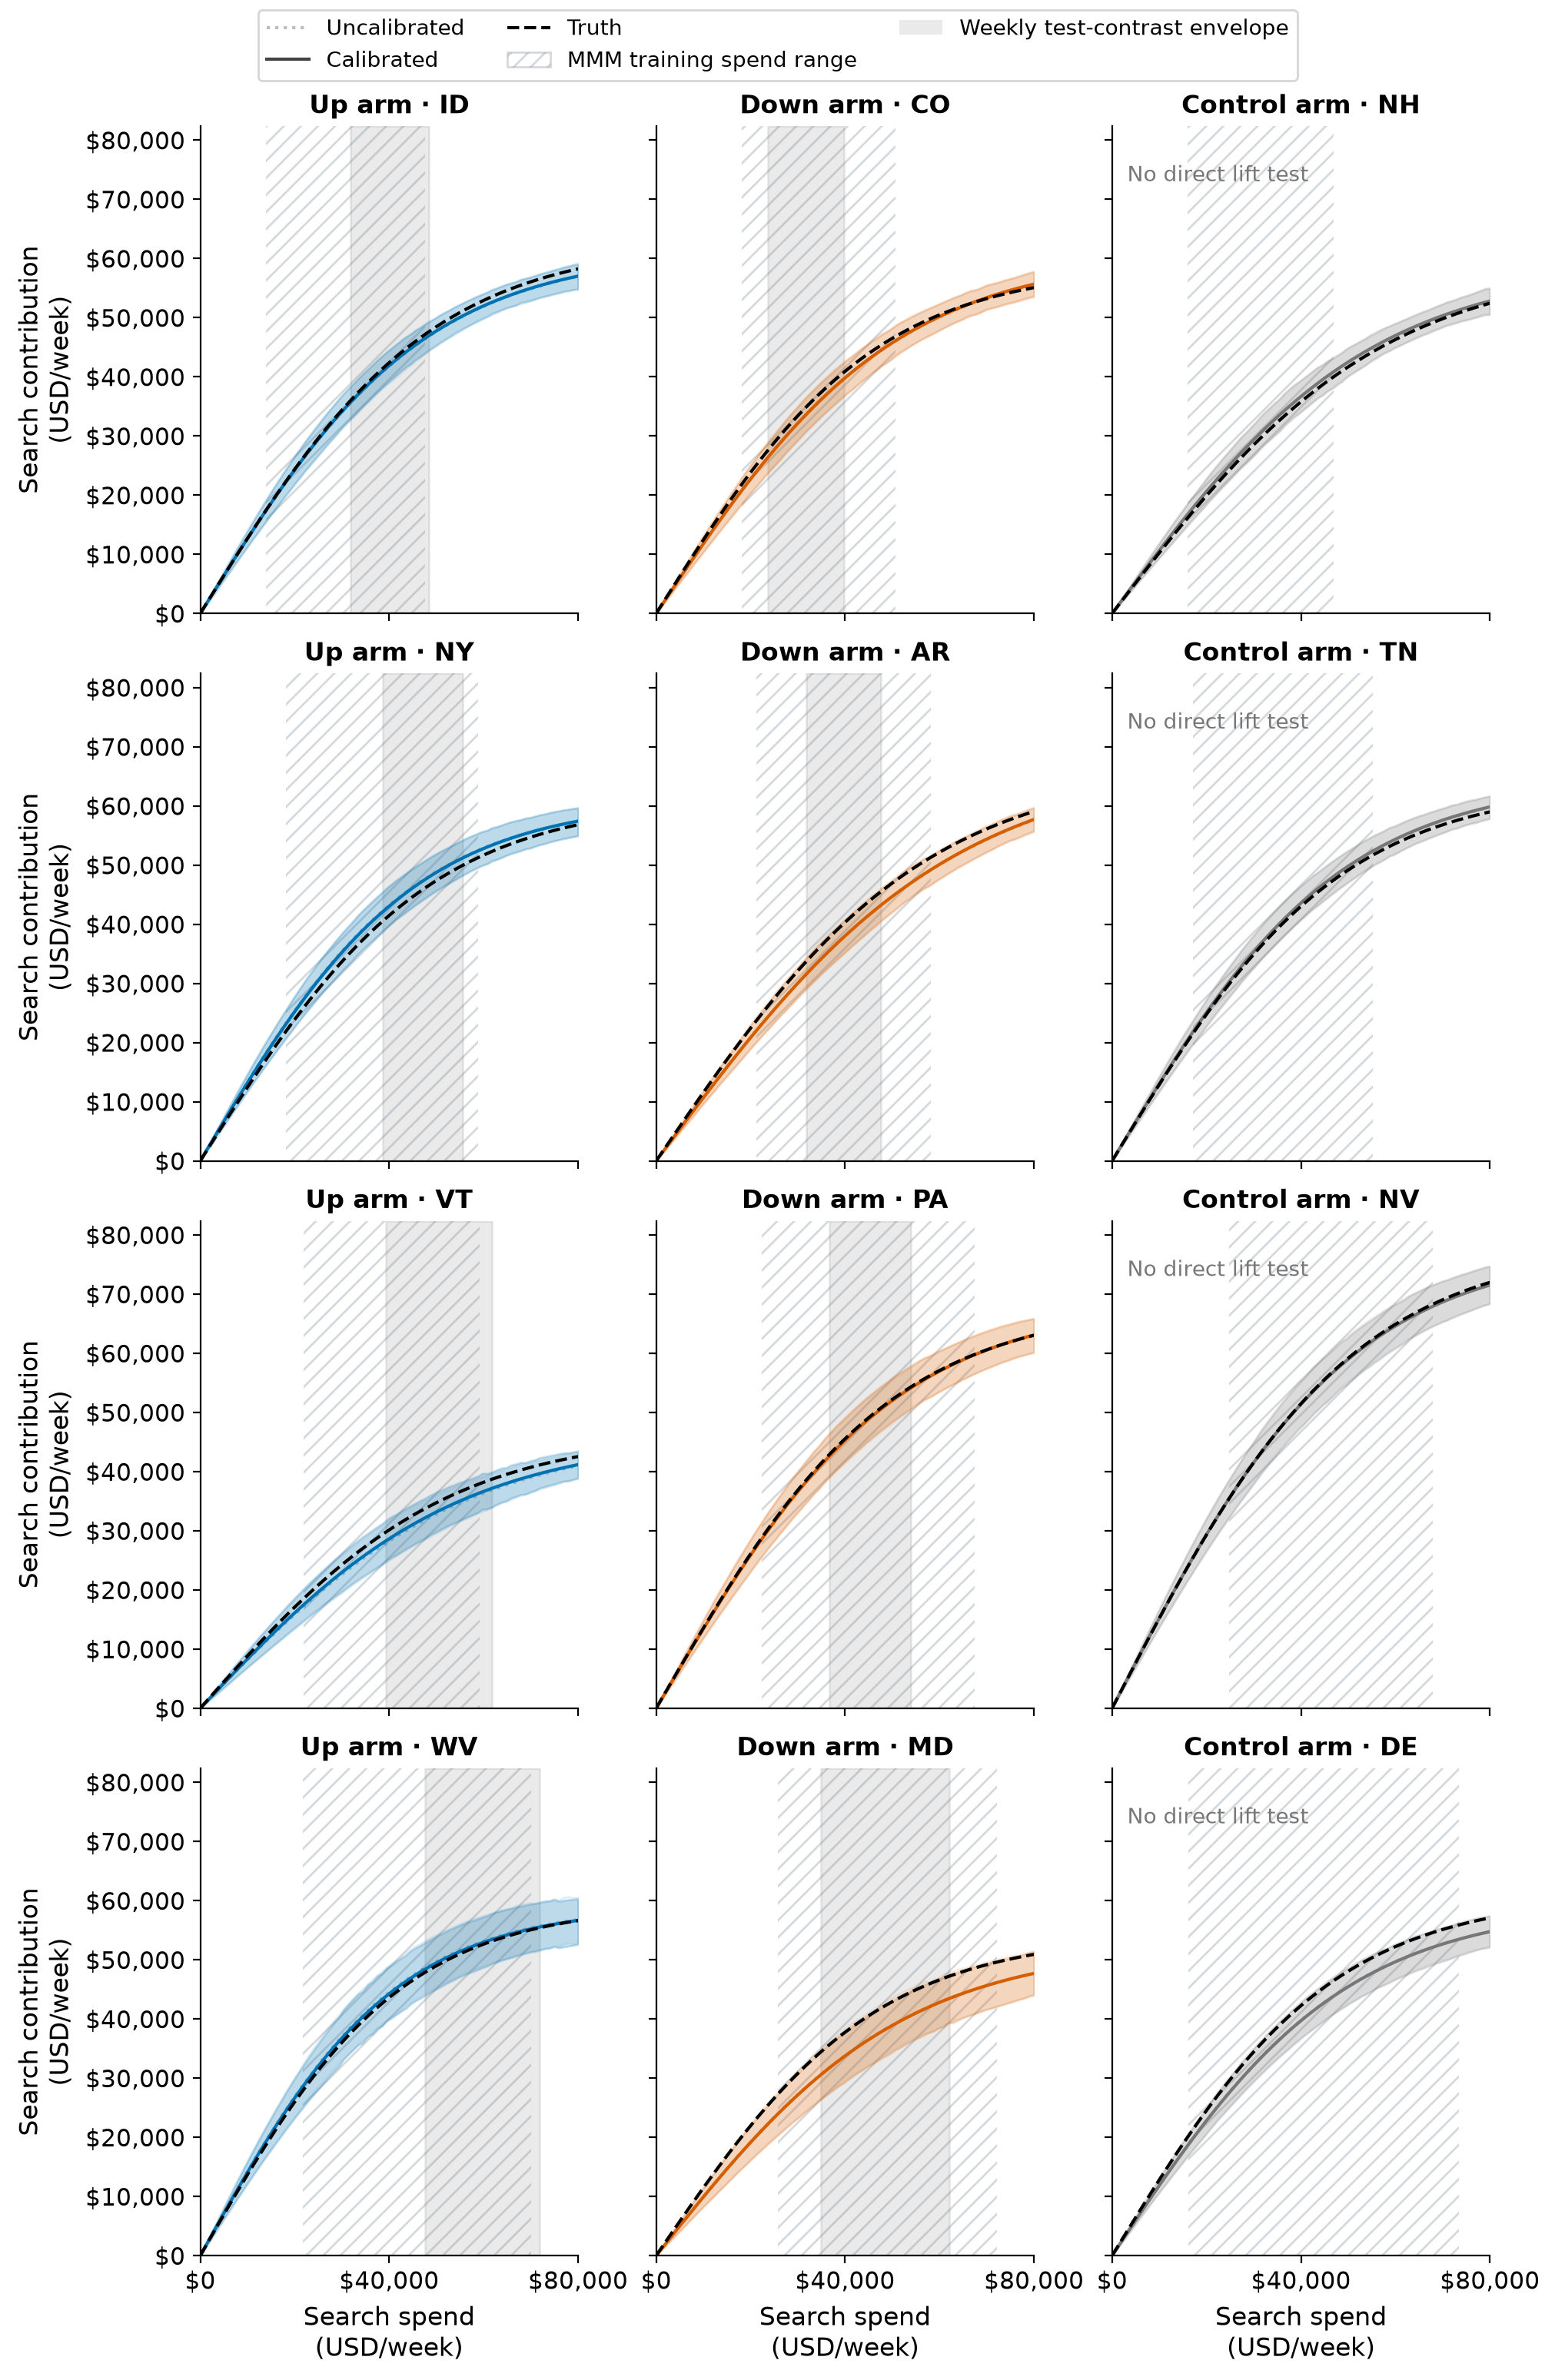

In [22]:
spend_grid = np.linspace(0, 80_000, 80)


def response_draws(idata):
    p = idata.posterior
    spend = xr.DataArray(spend_grid / SCALE, dims="spend", coords={"spend": spend_grid})
    return SCALE * p.saturation_beta * np.tanh(p.saturation_lam * spend / 2)


curve_draws = {
    "Uncalibrated": response_draws(idata_uncalibrated),
    "Calibrated": response_draws(idata_calibrated),
}


def plot_response_by_arm(channel, examples):
    example_geos = [g for _, g in examples]
    n_rows = len(examples) // 3
    posterior_upper = max(
        float(
            az.hdi(draws.sel(geo=example_geos, channel=channel), prob=0.94)
            .sel(ci_bound="upper")
            .max()
        )
        for draws in curve_draws.values()
    )
    c = channels.index(channel)
    truth_upper = SCALE * true_beta[[geos.index(g) for g in example_geos], c].max()
    curve_upper = 1.05 * max(posterior_upper, truth_upper)
    fig, axes = plt.subplots(
        n_rows,
        3,
        figsize=(FIG_WIDTH, FIG_HEIGHT * (1.1 * n_rows)),
        sharex=True,
        sharey=True,
    )
    for col, arm in enumerate(["up", "down", "control"]):
        members = [g for example_arm, g in examples if example_arm == arm]
        color = ARM_COLORS[arm] if channel == "search" else CHANNEL_COLORS[channel]
        for row, g in enumerate(members):
            ax = axes[row, col]
            training_values = X_train.loc[X_train.geo == g, channel]
            ax.axvspan(
                training_values.min(),
                training_values.max(),
                facecolor="none",
                edgecolor=COLOR_DONOR,
                hatch="///",
                linewidth=0,
                alpha=0.35,
                zorder=0,
            )
            for label, alpha, style in [
                ("Uncalibrated", 0.35, ":"),
                ("Calibrated", 1.0, "-"),
            ]:
                draws = curve_draws[label].sel(geo=g, channel=channel)
                hdi = az.hdi(draws, prob=0.94)
                ax.fill_between(
                    spend_grid,
                    hdi.sel(ci_bound="lower"),
                    hdi.sel(ci_bound="upper"),
                    color=color,
                    alpha=alpha * 0.2,
                )
                ax.plot(
                    spend_grid,
                    draws.mean(["chain", "draw"]),
                    color=color,
                    alpha=alpha,
                    linestyle=style,
                )
            if channel == "search" and arm in ["up", "down"]:
                before = spend_baseline.loc[window, (g, "search")]
                after = spend_realized.loc[window, (g, "search")]
                ax.axvspan(
                    min(before.min(), after.min()),
                    max(before.max(), after.max()),
                    color=COLOR_CONTROL,
                    alpha=0.15,
                    zorder=0,
                )
            else:
                ax.text(
                    0.04,
                    0.92,
                    "No direct lift test",
                    transform=ax.transAxes,
                    color=COLOR_CONTROL,
                    fontsize=10,
                    va="top",
                )
            i = geos.index(g)
            truth = (
                SCALE
                * true_beta[i, c]
                * np.tanh(true_lam[i, c] * spend_grid / SCALE / 2)
            )
            ax.plot(spend_grid, truth, color="black", linestyle="--")
            ax.set_title(f"{arm.title()} arm · {g}", fontsize=12, fontweight="bold")
            ax.xaxis.set_major_formatter(USD)
            ax.set_xticks([0, 40_000, 80_000])
            ax.yaxis.set_major_formatter(USD)
            ax.set(xlim=(0, 80_000), ylim=(0, curve_upper))
            if col == 0:
                ax.set_ylabel(f"{channel.title()} contribution\n(USD/week)")
            if row == len(members) - 1:
                ax.set_xlabel(f"{channel.title()} spend\n(USD/week)")
    legend_color = "#444444" if channel == "search" else CHANNEL_COLORS[channel]
    handles = [
        Line2D(
            [], [], color=legend_color, alpha=0.35, linestyle=":", label="Uncalibrated"
        ),
        Line2D([], [], color=legend_color, label="Calibrated"),
        Line2D([], [], color="black", linestyle="--", label="Truth"),
        Patch(
            facecolor="none",
            edgecolor=COLOR_DONOR,
            hatch="///",
            alpha=0.35,
            label="MMM training spend range",
        ),
    ]
    if channel == "search":
        handles.append(
            Patch(
                facecolor=COLOR_CONTROL,
                alpha=0.15,
                label="Weekly test-contrast envelope",
            )
        )
    fig.legend(handles=handles, loc="outside upper center", ncol=3, fontsize=10)
    plt.show()


plot_response_by_arm("search", curve_examples)

**Caption:** Search response curves for four baseline-spend-selected geos in each arm. Columns are up, down, and control, colored blue, orange, and gray respectively. Light/dotted curves are uncalibrated posterior means, dark/solid curves are calibrated means, bands are pointwise 94% HDIs, and black dashed curves are known truth. Hatched spans mark each geo's min–max training spend; solid gray spans cover the envelope of all eight weekly baseline/delivered search-spend pairs.

Only the up and down columns have direct experimental search constraints. Control panels say "No direct lift test." Historical training ranges and experiment envelopes are separate references. The experiment constrains the average of eight weekly contrasts, not every point inside the shaded envelope.

The experiment constrains an **average of weekly response differences**, not absolute channel contributions. Curves can agree on that local difference while remaining vertically far apart. Control-market estimates can change indirectly through the shared model; compare their truth curves to assess recovery rather than treating an unchanged estimate as evidence of accuracy.

In [23]:
metric_rows = []
for label, draws in curve_draws.items():
    hdi = az.hdi(draws, prob=0.94)
    for g in geos:
        i = geos.index(g)
        for channel in channels:
            c = channels.index(channel)
            selected = draws.sel(geo=g, channel=channel)
            true_curve = (
                SCALE
                * true_beta[i, c]
                * np.tanh(true_lam[i, c] * spend_grid / SCALE / 2)
            )
            bounds = hdi.sel(geo=g, channel=channel)
            metric_rows.append(
                {
                    "model": label,
                    "arm": geo_arm[g],
                    "channel": channel,
                    "MAE (USD/week)": float(
                        np.abs(selected.mean(["chain", "draw"]) - true_curve).mean()
                    ),
                    "HDI width (USD/week)": float(
                        (
                            bounds.sel(ci_bound="upper") - bounds.sel(ci_bound="lower")
                        ).mean()
                    ),
                    "Truth coverage": float(
                        (
                            (true_curve >= bounds.sel(ci_bound="lower"))
                            & (true_curve <= bounds.sel(ci_bound="upper"))
                        ).mean()
                    ),
                }
            )
curve_metrics = pd.DataFrame(metric_rows).groupby(["channel", "arm", "model"]).mean()
display(curve_metrics.xs("search", level="channel").round(2))

MAE (USD/week)  HDI width (USD/week)  Truth coverage
arm     model                                                             
control Calibrated            976.80               5066.53            1.00
        Uncalibrated          971.27               5087.91            1.00
down    Calibrated           1362.99               5552.91            0.93
        Uncalibrated         1388.39               5550.73            0.94
up      Calibrated            971.61               4922.36            0.94
        Uncalibrated         1004.82               4945.41            0.94

Search curve error and interval width are averaged over the displayed 0–80,000 USD/week grid, then across geos within each arm. Coverage is the fraction of grid points whose truth lies in the pointwise 94% HDI. These summaries include extrapolation beyond observed spend; they are not forecast scores or population bias estimates. Search in the active arms is directly calibrated; control-search estimates can move only through the shared model and parameter tradeoffs.

Compare each arm separately. An improvement in experiment-average response need not recover absolute contribution or the full curve. Controls have no direct experimental constraints, so any movement reflects pooling and the joint attribution model. The next table checks Monte Carlo diagnostics before interpreting small differences in recovery.

Both models already recover search response well in this simulation. The shared weekly baseline represents common revenue variation before calibration is added. Calibration slightly improves grid error in the active arms, with little change in controls; it is additional evidence, rather than the explanation for all successful recovery.

In [24]:
curve_diagnostics = []
for label, draws in curve_draws.items():
    central_curves = draws.sel(spend=spend_grid[[20, 40, 60]])
    curve_diagnostics.append(
        {
            "model": label,
            "curve max R-hat": float(az.rhat(central_curves).max()),
            "curve min ESS": float(az.ess(central_curves).min()),
        }
    )
display(pd.DataFrame(curve_diagnostics).round(4))
print(f"Total elapsed: {(time.perf_counter() - started) / 60:.1f} minutes")

,model,curve max R-hat,curve min ESS
0,Uncalibrated,1.0048,910.2848
1,Calibrated,1.0098,652.2580


Total elapsed: 57.2 minutes


Compare curve R-hat and ESS with the targets above. Any shortfall limits precise Monte Carlo claims even when the point estimates move toward truth.

### Local returns: marginal ROAS at operating spend

**Stakeholder question: Have we recovered the revenue generated by the next dollar of search spend at our operating spend level?**

We compare marginal-ROAS curves with truth and check accuracy at each treated geo's mean baseline spend during the experiment. A finite experiment directly informs a different return: **average incremental revenue divided by the assigned spend increment**. Here each week has a different ordinary budget, so we average its response difference across the eight weeks before dividing by the constant increment.

For a down geo, both the mean effect and spend increment are negative, so the ratio is positive: revenue lost per dollar cut. This is not total attributed revenue divided by total spend.

**Marginal ROAS** is the derivative at a particular operating spend. For this notebook's logistic curve, in original USD units,

$$
\operatorname{mROAS}_g(x)=f'_g(x)
=\frac{\beta_g\lambda_g}{2}\left[1-\tanh^2\!\left(\frac{\lambda_gx}{2S}\right)\right],
\qquad S=100{,}000.
$$

For each week's concave curve, an up-test secant slope is below the derivative at that week's baseline, while a down-test secant is above it. Averaging over changing budgets is not generally equivalent to taking the derivative at mean spend. That point derivative still depends on curvature, priors, and pooling. Both ratios are contemporaneous because the simulator has no carryover.

We compute both quantities for every posterior draw in all 32 treated geos. The figure retains the same four examples per active arm as the search saturation plot, selected by fixed baseline-spend ranks before effect estimation. The summary table covers all treated geos.

In [25]:
def marginal_roas(lam, beta, spend):
    return beta * lam / 2 * (1 - np.tanh(lam * spend / (2 * SCALE)) ** 2)


lift_geo = xr.DataArray(
    lift_rows.geo.to_numpy(),
    dims="lift_geo",
    coords={"lift_geo": lift_rows.geo.to_numpy()},
)
weekly_before = xr.DataArray(
    search_baseline.to_numpy().T,
    dims=("lift_geo", "lift_week"),
    coords={"lift_geo": lift_rows.geo.to_numpy(), "lift_week": window},
)
weekly_after = xr.DataArray(
    search_delivered.to_numpy().T,
    dims=("lift_geo", "lift_week"),
    coords=weekly_before.coords,
)
baseline_spend = weekly_before.mean("lift_week")
spend_change = (weekly_after - weekly_before).mean("lift_week")
local_returns = {}
for label, idata in [
    ("Uncalibrated", idata_uncalibrated),
    ("Calibrated", idata_calibrated),
]:
    p = idata.posterior.sel(geo=lift_geo, channel="search")
    before = (
        SCALE
        * p.saturation_beta
        * np.tanh(p.saturation_lam * weekly_before / (2 * SCALE))
    )
    after = (
        SCALE
        * p.saturation_beta
        * np.tanh(p.saturation_lam * weekly_after / (2 * SCALE))
    )
    local_returns[label] = xr.Dataset(
        {
            "interval_average": (after - before).mean("lift_week") / spend_change,
            "marginal_at_baseline": marginal_roas(
                p.saturation_lam, p.saturation_beta, baseline_spend
            ),
        }
    )

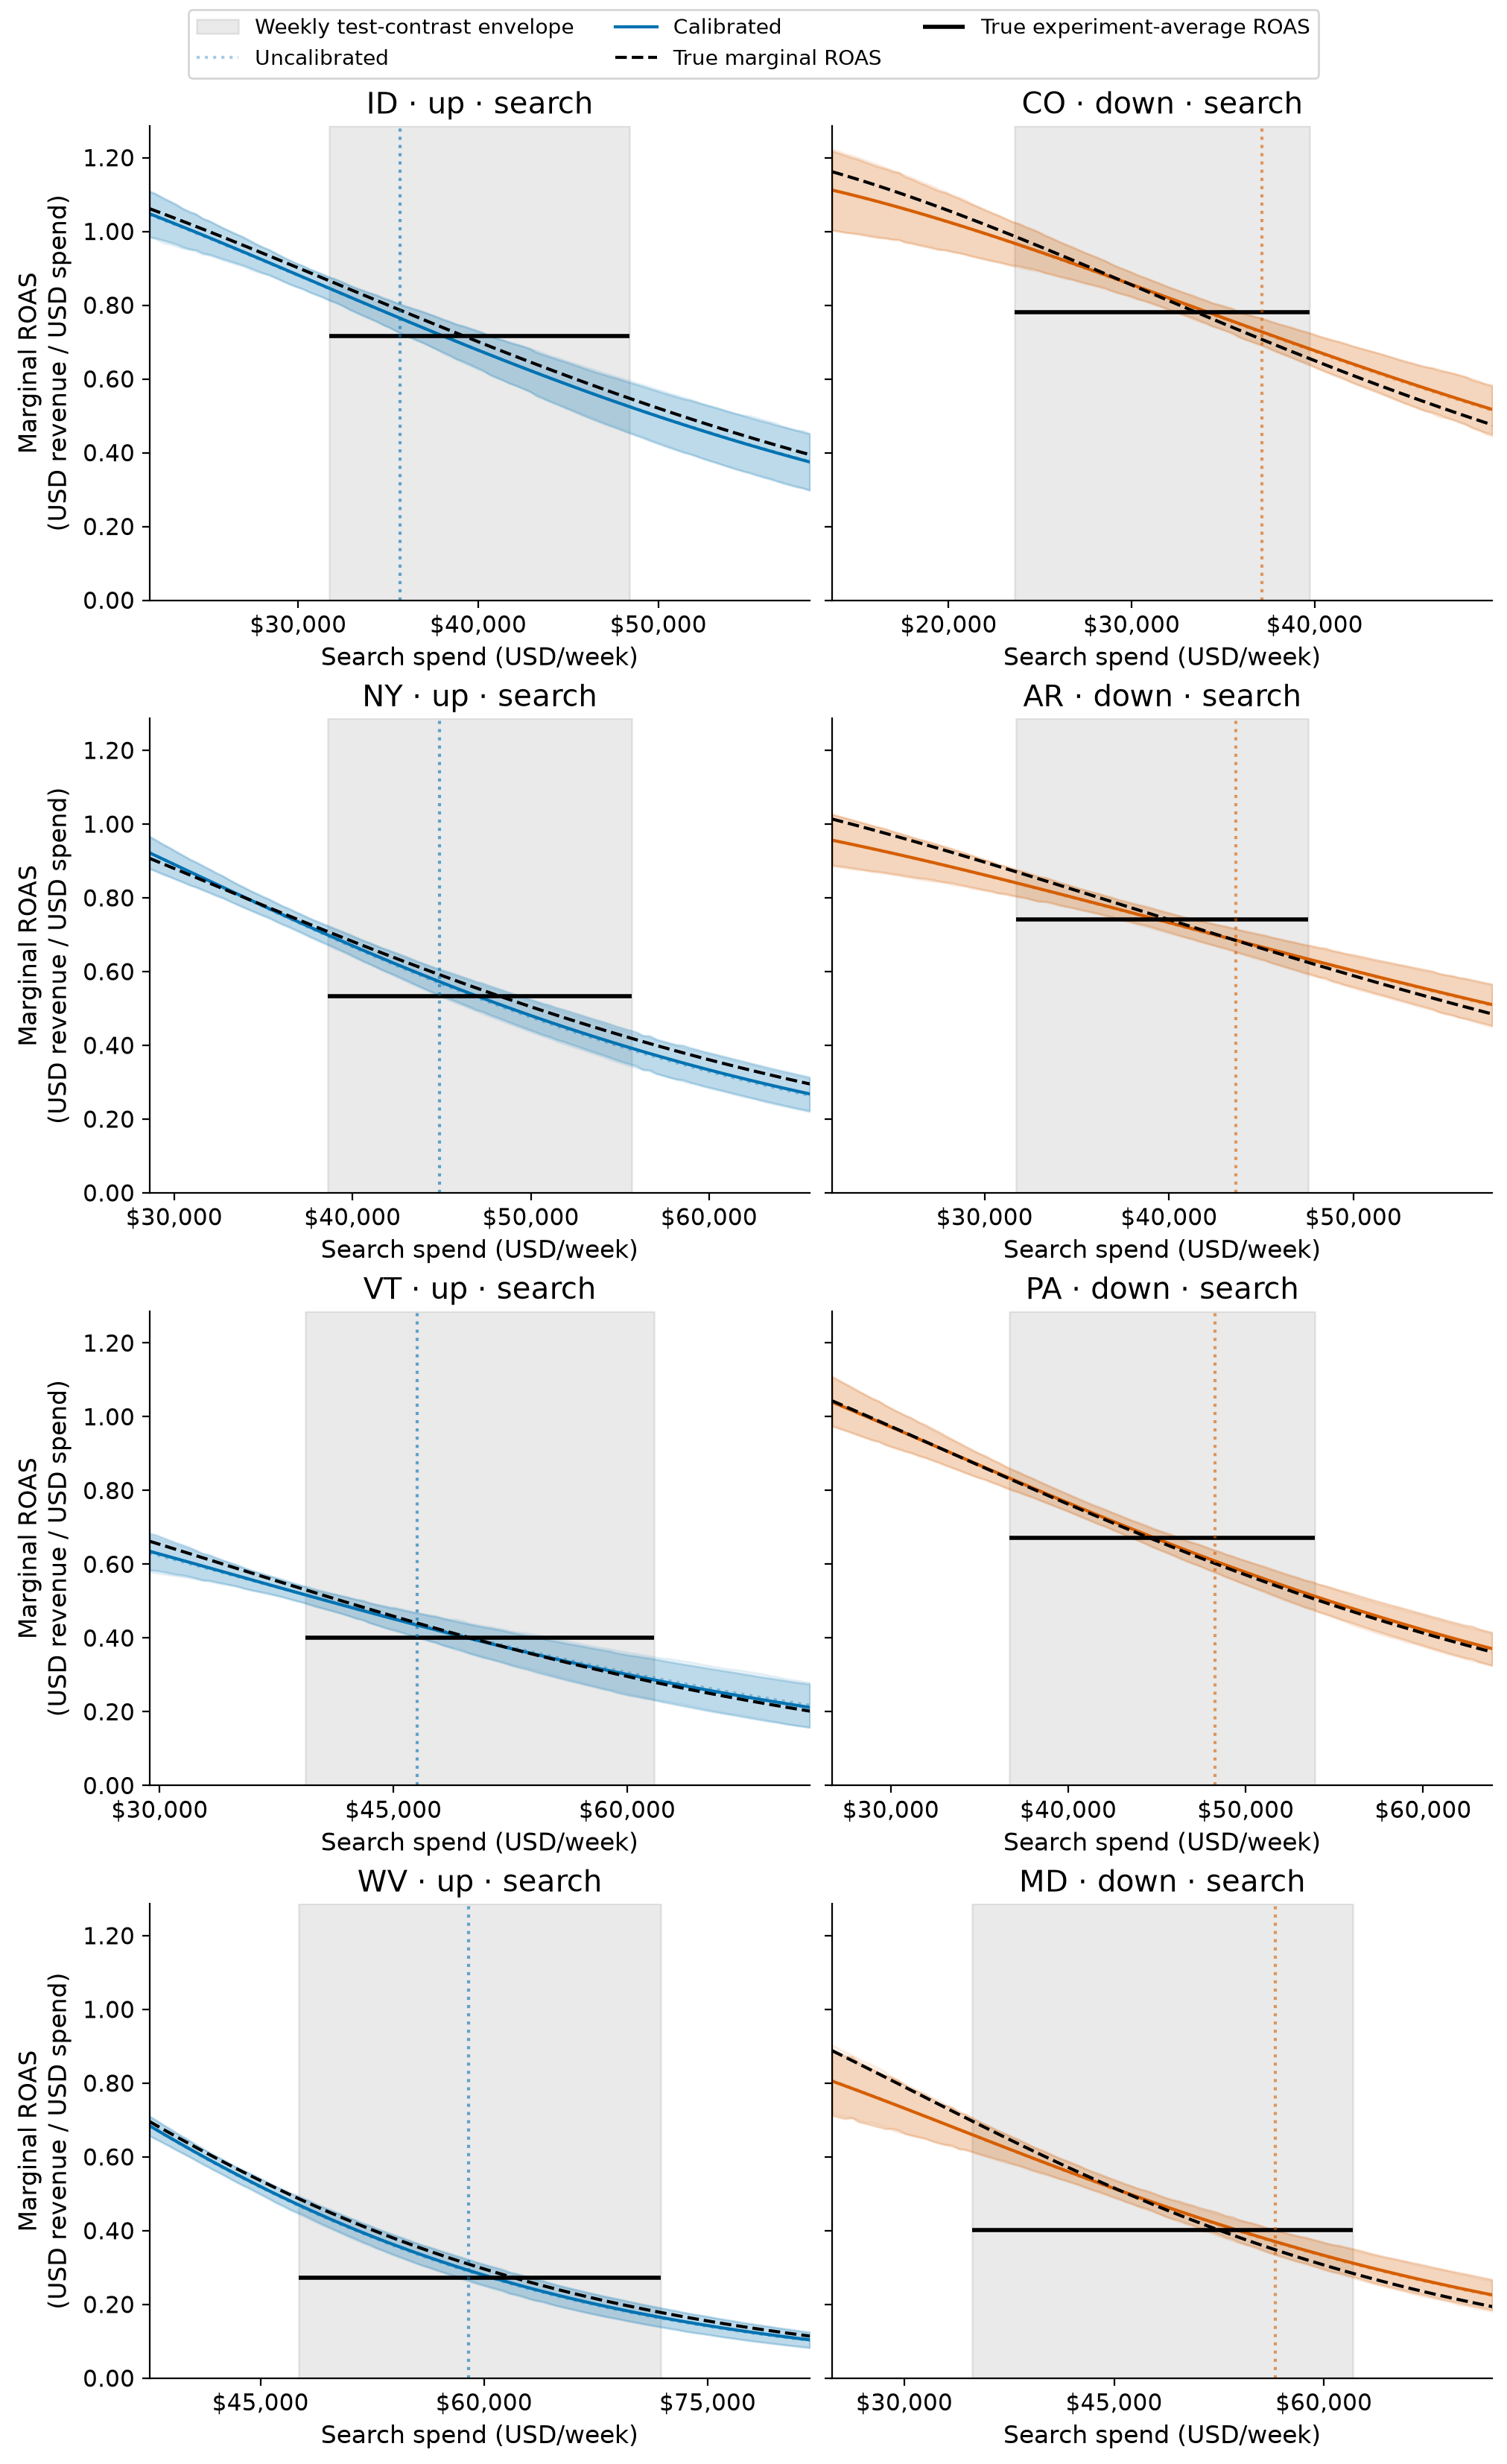

In [26]:
fig, axes = plt.subplots(4, 2, figsize=(FIG_WIDTH, FIG_HEIGHT * 4.7), sharey=True)
local_upper = 0.0
for ax, (arm, g) in zip(axes.flat, return_examples, strict=True):
    dose = lift_rows.set_index("geo").loc[g]
    before = spend_baseline.loc[window, (g, "search")]
    after = spend_realized.loc[window, (g, "search")]
    lower, upper = min(before.min(), after.min()), max(before.max(), after.max())
    local_spend = np.linspace(max(0, lower - 10_000), upper + 10_000, 100)
    spend = xr.DataArray(local_spend, dims="spend")
    ax.axvspan(
        lower,
        upper,
        color=COLOR_CONTROL,
        alpha=0.15,
        label="Weekly test-contrast envelope",
    )
    for label, idata, alpha, style in [
        ("Uncalibrated", idata_uncalibrated, 0.35, ":"),
        ("Calibrated", idata_calibrated, 1.0, "-"),
    ]:
        p = idata.posterior.sel(geo=g, channel="search")
        draws = marginal_roas(p.saturation_lam, p.saturation_beta, spend)
        hdi = az.hdi(draws, prob=0.94)
        ax.fill_between(
            local_spend,
            hdi.sel(ci_bound="lower"),
            hdi.sel(ci_bound="upper"),
            color=ARM_COLORS[arm],
            alpha=alpha * 0.2,
        )
        ax.plot(
            local_spend,
            draws.mean(["chain", "draw"]),
            color=ARM_COLORS[arm],
            alpha=alpha,
            linestyle=style,
            label=label,
        )
        local_upper = max(local_upper, float(hdi.sel(ci_bound="upper").max()))
    i = geos.index(g)
    true_marginal = marginal_roas(true_lam[i, 0], true_beta[i, 0], local_spend)
    ax.plot(
        local_spend,
        true_marginal,
        color="black",
        linestyle="--",
        label="True marginal ROAS",
    )
    ax.hlines(
        true_lift[g] / dose.delta_x,
        lower,
        upper,
        color="black",
        linewidth=2,
        label="True experiment-average ROAS",
    )
    local_upper = max(local_upper, float(true_marginal.max()))
    ax.axvline(dose.x, color=ARM_COLORS[arm], linestyle=":", alpha=0.6)
    ax.set_title(f"{g} · {arm} · search")
    ax.set_xlabel("Search spend (USD/week)")
    ax.set_xlim(local_spend[0], local_spend[-1])
    ax.xaxis.set_major_formatter(USD)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:.2f}"))
for ax in axes[:, 0]:
    ax.set_ylabel("Marginal ROAS\n(USD revenue / USD spend)")
axes[0, 0].set_ylim(0, local_upper * 1.05)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper center", ncol=3, fontsize=10)
plt.show()

**Caption:** Local search marginal ROAS for four predetermined geos per active arm. Lines are posterior means with pointwise 94% HDIs; light/dotted is uncalibrated and dark/solid calibrated. Black dashed curves are true derivatives. Gray spans enclose all eight weekly baseline/delivered spend pairs, and arm-colored vertical dotted lines mark mean baseline spend. Black horizontal segments show true experiment-average incremental ROAS; they are neither point derivatives nor a secant at mean spend.

The experiment constrains the average weekly response difference. Its derivative at mean spend is a separate recovery check. The tables below compare both against truth and retain the counterfactual and marginal-summary uncertainty limitations.

In [27]:
# Check the experimental contrast against the model's registered deterministic.
registered_lift = idata_calibrated.posterior[
    "multi_arm_geo_lift_model_estimated_lift_original_scale"
]
np.testing.assert_allclose(
    (local_returns["Calibrated"].interval_average * spend_change)
    .transpose("chain", "draw", "lift_geo")
    .values,
    registered_lift.transpose("chain", "draw", ...).values,
)

geo_indices = [geos.index(g) for g in lift_rows.geo]
true_returns = xr.Dataset(
    {
        "interval_average": xr.DataArray(
            true_lift.loc[lift_rows.geo].to_numpy(),
            dims="lift_geo",
            coords=lift_geo.coords,
        )
        / spend_change,
        "marginal_at_baseline": marginal_roas(
            xr.DataArray(
                true_lam[geo_indices, 0], dims="lift_geo", coords=lift_geo.coords
            ),
            xr.DataArray(
                true_beta[geo_indices, 0], dims="lift_geo", coords=lift_geo.coords
            ),
            baseline_spend,
        ),
    }
)
return_metrics = []
return_labels = {
    "interval_average": "Average over experiment weeks",
    "marginal_at_baseline": "Marginal at mean baseline spend",
}
for quantity, description in return_labels.items():
    for label, draws in local_returns.items():
        selected = draws[quantity]
        hdi = az.hdi(selected, prob=0.94)
        return_metrics.append(
            {
                "Quantity": description,
                "Model": label,
                "MAE (USD/USD)": float(
                    np.abs(
                        selected.mean(["chain", "draw"]) - true_returns[quantity]
                    ).mean()
                ),
                "Mean HDI width (USD/USD)": float(
                    (hdi.sel(ci_bound="upper") - hdi.sel(ci_bound="lower")).mean()
                ),
                "Max R-hat": float(az.rhat(selected).max()),
                "Min ESS": float(az.ess(selected).min()),
            }
        )
display(pd.DataFrame(return_metrics).set_index(["Quantity", "Model"]).round(3))

MAE (USD/USD)  \
Quantity                        Model                         
Average over experiment weeks   Uncalibrated          0.013   
                                Calibrated            0.013   
Marginal at mean baseline spend Uncalibrated          0.013   
                                Calibrated            0.013   

                                              Mean HDI width (USD/USD)  \
Quantity                        Model                                    
Average over experiment weeks   Uncalibrated                     0.067   
                                Calibrated                       0.066   
Marginal at mean baseline spend Uncalibrated                     0.068   
                                Calibrated                       0.067   

                                              Max R-hat   Min ESS  
Quantity                        Model                              
Average over experiment weeks   Uncalibrated      1.001  4516.475  
                                Calibrated        1.001  4652.008  
Marginal at mean baseline spend Uncalibrated      1.001  4878.202  
                                Calibrated        1.001  5063.420

Experiment-average return checks recovery of the finite weekly contrasts per dollar of assigned spend. Marginal ROAS at mean baseline spend checks a point derivative. Read both against their uncertainty and Monte Carlo diagnostics; agreement with the calibration inputs alone does not establish full-curve recovery or a profit-maximizing budget.

The historical panel and shared baseline already yield accurate local search returns here. Calibration changes the estimates only slightly. A small decrease in posterior-mean error is not evidence of a large practical improvement when the uncertainty bands mostly overlap.

### Supporting analysis: the untested display channel

Display budgets continued their ordinary variation in every arm, and no display lift measurements enter calibration. Its inferred contribution can nevertheless move when the joint MMM reallocates revenue between search, display, and baseline components. The learned amplitude and curvature distributions also share information between geos within each channel. These are indirect changes in attribution, rather than a measured display treatment effect.

Both display figures use a **3 × 3 layout**: columns are up, down, and control; rows show three example geos from each arm. We choose the examples at evenly spaced ranks from lowest to highest baseline **display** spend before inspecting effects, and use the same nine geos in both figures. The search figures retain their four-row layouts.

#### Display contributions across spend levels

**Stakeholder question: Does calibrating search also improve recovery of the untested display channel's revenue contribution?**

Compare both MMM curves with the known display truth. All display contribution panels share a channel-specific revenue scale. The table summarizes recovery across all 48 geos, rather than only the nine examples.

An untested channel can remain biased even when its budgets are independent of demand. Both channels share a local budget driver. Conditioning on search, which also responds to latent demand, can induce a negative partial association between display and demand. A model that fails to represent common demand can therefore shrink display attribution toward zero. Our shared weekly baseline gives that variation a non-media explanation. Calibrating search and pooling response parameters can further change the attribution tradeoff, but neither supplies a display experiment or guarantees indirect improvement.

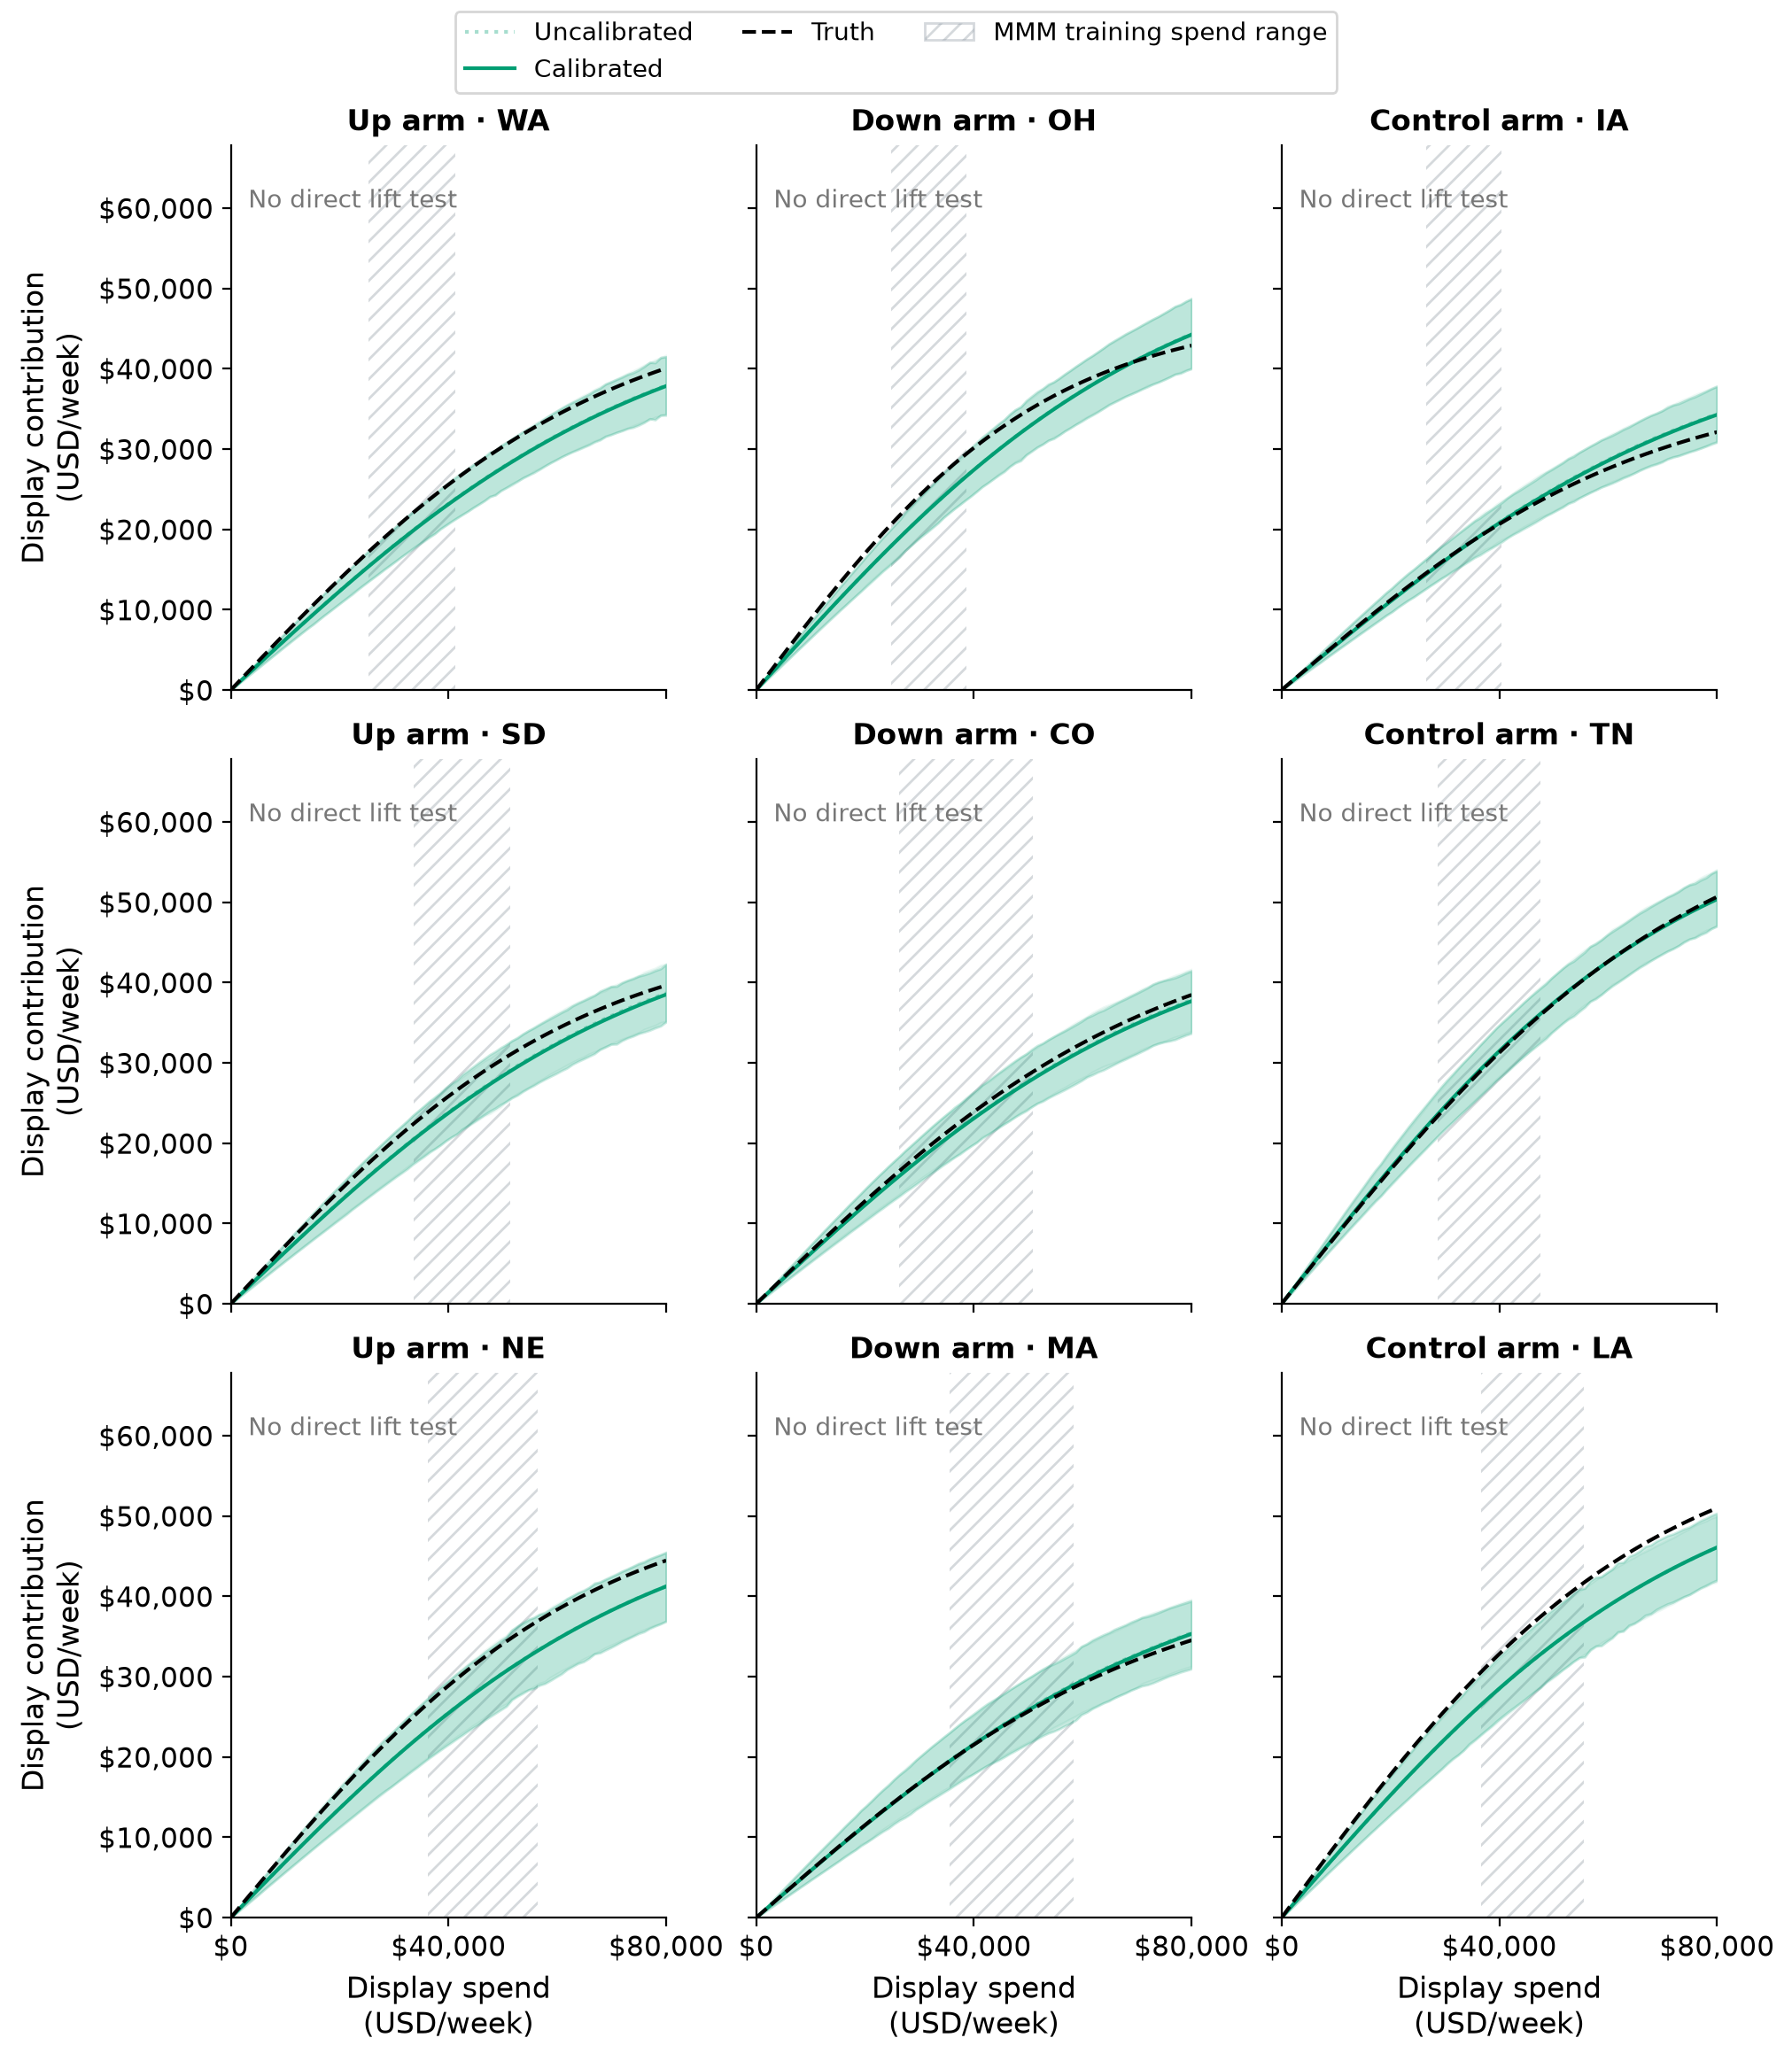

In [28]:
plot_response_by_arm("display", display_examples)

**Caption:** Display response curves for three baseline-display-spend-selected geos per arm, with up, down, and control columns. Green identifies display; light/dotted and dark/solid posterior means denote uncalibrated and calibrated fits, with pointwise 94% HDI bands. Black dashed curves are known truth. Hatched spans mark each geo's min–max display training spend. Every panel has no direct lift test.

The calibrated display estimates can move even though only search is experimentally constrained. This does not establish improved display attribution: the table below checks curve error and uncertainty against truth across all geos.

In [29]:
display(curve_metrics.xs("display", level="channel").round(2))

MAE (USD/week)  HDI width (USD/week)  Truth coverage
arm     model                                                             
control Calibrated           1392.56               5679.40            0.76
        Uncalibrated         1399.59               5542.76            0.74
down    Calibrated           1738.05               5476.06            0.74
        Uncalibrated         1706.41               5364.09            0.73
up      Calibrated           1500.38               5598.52            0.92
        Uncalibrated         1493.63               5453.90            0.89

These display summaries use the same grid, error, interval-width, and pointwise-coverage definitions as the search table. Changes in an untested channel remain dependent on the joint model and imperfect separation of the shared baseline from media response; narrower intervals alone do not establish better recovery.

The display changes are small and mixed: the control-arm grid error decreases slightly, while the active-arm errors increase slightly. These movements are small compared with the posterior bands. They do not establish consistent recovery gains for the untested channel.

#### Display marginal ROAS at operating spend

**Stakeholder question: Does search calibration also improve the estimated revenue from the next dollar of display spend?**

We evaluate the same marginal-ROAS derivative used for search, now with each geo's display saturation parameters. Display has no experimental spend contrast, so there is no lift-test interval or experimental return estimate to overlay. The vertical reference marks mean business-as-usual display spend during the experiment; hatching marks the observed training range. Compare posterior curves with truth, and use the table to check recovery at that operating spend across all 48 geos.

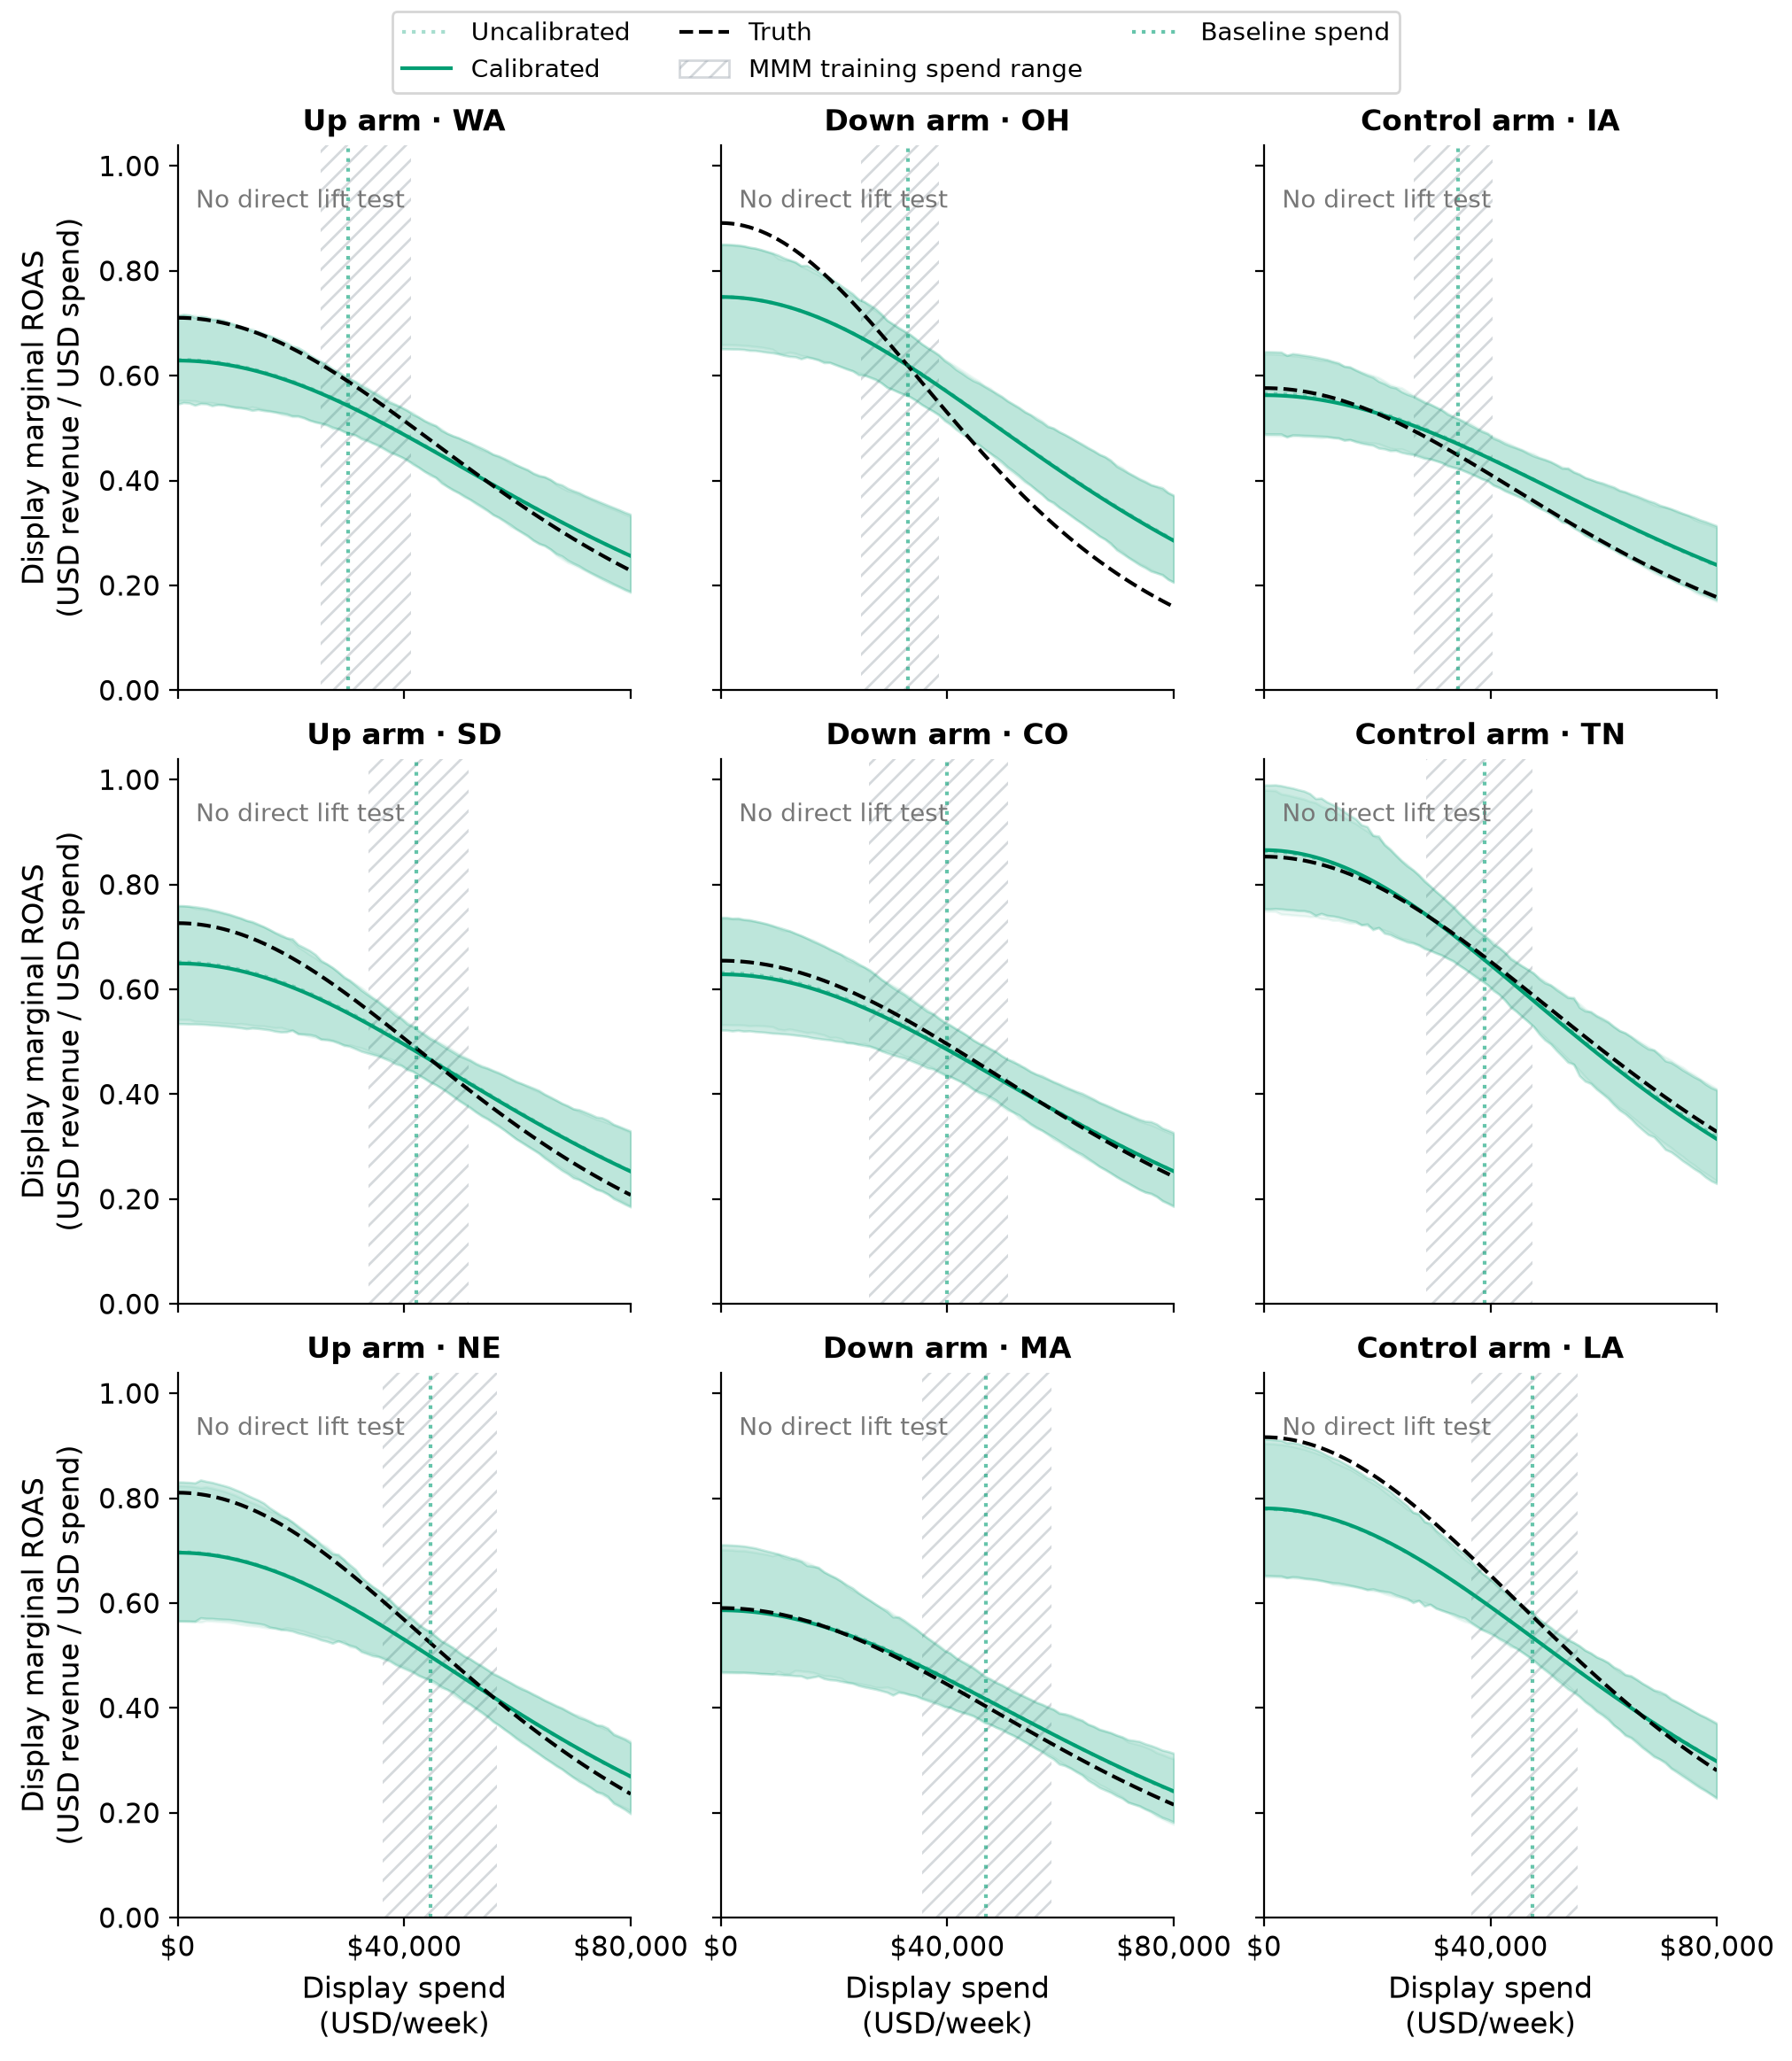

In [30]:
fig, axes = plt.subplots(
    3, 3, figsize=(FIG_WIDTH, FIG_HEIGHT * 3.3), sharex=True, sharey=True
)
display_return_upper = 0.0
color = CHANNEL_COLORS["display"]
for col, arm in enumerate(["up", "down", "control"]):
    members = [g for a, g in display_examples if a == arm]
    for row, g in enumerate(members):
        ax = axes[row, col]
        training_values = X_train.loc[X_train.geo == g, "display"]
        ax.axvspan(
            training_values.min(),
            training_values.max(),
            facecolor="none",
            edgecolor=COLOR_DONOR,
            hatch="///",
            linewidth=0,
            alpha=0.35,
            zorder=0,
        )
        spend = xr.DataArray(spend_grid, dims="spend", coords={"spend": spend_grid})
        for label, idata, alpha, style in [
            ("Uncalibrated", idata_uncalibrated, 0.35, ":"),
            ("Calibrated", idata_calibrated, 1.0, "-"),
        ]:
            params = idata.posterior.sel(geo=g, channel="display")
            draws = marginal_roas(params.saturation_lam, params.saturation_beta, spend)
            hdi = az.hdi(draws, prob=0.94)
            ax.fill_between(
                spend_grid,
                hdi.sel(ci_bound="lower"),
                hdi.sel(ci_bound="upper"),
                color=color,
                alpha=alpha * 0.2,
            )
            ax.plot(
                spend_grid,
                draws.mean(["chain", "draw"]),
                color=color,
                alpha=alpha,
                linestyle=style,
                label=label,
            )
            display_return_upper = max(
                display_return_upper, float(hdi.sel(ci_bound="upper").max())
            )
        i = geos.index(g)
        true_marginal = marginal_roas(true_lam[i, 1], true_beta[i, 1], spend_grid)
        ax.plot(spend_grid, true_marginal, color="black", linestyle="--")
        display_return_upper = max(display_return_upper, float(true_marginal.max()))
        ax.axvline(
            spend_baseline.loc[window, (g, "display")].mean(),
            color=color,
            linestyle=":",
            alpha=0.6,
        )
        ax.text(
            0.04,
            0.92,
            "No direct lift test",
            transform=ax.transAxes,
            color=COLOR_CONTROL,
            fontsize=10,
            va="top",
        )
        ax.set_title(f"{arm.title()} arm · {g}", fontsize=12, fontweight="bold")
        ax.set_xlim(0, 80_000)
        ax.set_xticks([0, 40_000, 80_000])
        ax.xaxis.set_major_formatter(USD)
        ax.yaxis.set_major_formatter(StrMethodFormatter("{x:.2f}"))
        if col == 0:
            ax.set_ylabel("Display marginal ROAS\n(USD revenue / USD spend)")
        if row == 2:
            ax.set_xlabel("Display spend\n(USD/week)")
axes[0, 0].set_ylim(0, display_return_upper * 1.05)
fig.legend(
    handles=[
        Line2D([], [], color=color, alpha=0.35, linestyle=":", label="Uncalibrated"),
        Line2D([], [], color=color, label="Calibrated"),
        Line2D([], [], color="black", linestyle="--", label="Truth"),
        Patch(
            facecolor="none",
            edgecolor=COLOR_DONOR,
            hatch="///",
            alpha=0.35,
            label="MMM training spend range",
        ),
        Line2D([], [], color=color, linestyle=":", alpha=0.6, label="Baseline spend"),
    ],
    loc="outside upper center",
    ncol=3,
    fontsize=10,
)
plt.show()

**Caption:** Display marginal-ROAS curves for the same nine geos as the display saturation figure, arranged in up, down, and control columns. Lines are posterior means with pointwise 94% HDI bands; light/dotted is uncalibrated, dark/solid is calibrated, and black dashed is truth. Vertical green dotted lines mark mean business-as-usual display spend during the experiment; hatched spans show min–max training spend. There is no direct display lift test in any panel.

In [31]:
display_baselines = xr.DataArray(
    baseline[is_intervention, :, 1].mean(axis=0), dims="geo", coords={"geo": geos}
)
display_return_truth = xr.DataArray(
    marginal_roas(
        true_lam[:, 1], true_beta[:, 1], baseline[is_intervention, :, 1].mean(axis=0)
    ),
    dims="geo",
    coords={"geo": geos},
)
display_return_rows = []
for label, idata in [
    ("Uncalibrated", idata_uncalibrated),
    ("Calibrated", idata_calibrated),
]:
    params = idata.posterior.sel(channel="display")
    draws = marginal_roas(
        params.saturation_lam, params.saturation_beta, display_baselines
    )
    hdi = az.hdi(draws, prob=0.94)
    lower, upper = hdi.sel(ci_bound="lower"), hdi.sel(ci_bound="upper")
    display_return_rows.append(
        {
            "fit": label,
            "RMSE at baseline (USD/USD)": float(
                np.sqrt(
                    ((draws.mean(["chain", "draw"]) - display_return_truth) ** 2).mean()
                )
            ),
            "Mean 94% HDI width (USD/USD)": float((upper - lower).mean()),
            "94% interval coverage": float(
                (
                    (lower <= display_return_truth) & (display_return_truth <= upper)
                ).mean()
            ),
        }
    )
display_return_metrics = pd.DataFrame(display_return_rows).set_index("fit")
display(
    display_return_metrics.style.format(
        {
            "RMSE at baseline (USD/USD)": "{:.3f}",
            "Mean 94% HDI width (USD/USD)": "{:.3f}",
            "94% interval coverage": "{:.0%}",
        }
    )
)

,RMSE at baseline (USD/USD),Mean 94% HDI width (USD/USD),94% interval coverage
fit,,,
Uncalibrated,0.026,0.095,92%
Calibrated,0.026,0.095,94%


RMSE compares posterior-mean display marginal ROAS with truth at each geo's own baseline spend, then averages squared errors over all 48 geos before taking the square root. Interval width and pointwise coverage use the same spend points. These checks distinguish better recovery from a mere change in attribution or uncertainty. Any improvement for display is indirect and remains dependent on the joint model, priors, and imperfect separation of the shared baseline from media response.

Both fits recover display marginal ROAS at operating spend well in this simulation. Search calibration does not materially improve its RMSE; pointwise coverage increases alongside slightly wider intervals. Partial pooling makes indirect updates possible, but does not force them to improve every geo or channel.

## Summary and limitations

The example has one pre-intervention period and one experiment. Ordinary budget, demand, seasonality, and noise processes continue through both; only the assigned search increment changes. All 136 pre-intervention weeks train both stages. Experimental outcomes enter the MMM only through the estimated eight-week mean effects, with their full weekly spend paths retained for calibration. Equal up/down spend increments cancel financially without guaranteeing revenue neutrality.

Both saturation amplitudes and curvatures are free and partially pooled across geos within each channel. Calibration can therefore affect untested geos and the untested display channel indirectly. That sharing does not guarantee recovery: the shared baseline is estimated rather than observed, and attributing common demand changes versus correlated media response still depends on model assumptions. The contribution and marginal-return figures assess truth recovery separately, rather than treating any posterior movement as improvement.

With the shared baseline, the historical panel already recovers local returns well. Calibration adds only modest changes here, and does not materially improve untested display marginal ROAS. Successful recovery should not be attributed entirely to the experiment.

Each treated geo contributes one mean experimental contrast, not a full response curve. Geo/channel tradeoffs, partial-pooling assumptions, counterfactual error, shared donors, reused pre-period outcomes, and the marginal Normal approximation limit interpretation. A shared weekly baseline represents common non-media variation, but its adequacy and separation from media remain modeling assumptions. Inspect sampling diagnostics for population parameters and curves as well as individual parameters.

This notebook uses no carryover, an identity link, no spillovers, and an explicitly averaged temporal contrast. Fixed-spend experiments can use the standard scalar calibration API. Real carryover requires an estimand that accounts for the full adstock history. Adequate confounder adjustment and credible experiment design remain necessary.

:::{admonition} Further Reading
:class: seealso

- {ref}`mmm_geolift_calibration` introduces the standard fixed-spend calibration API.
- {ref}`mmm_multidimensional_example` explains geographic dimensions and hierarchical priors.
- [CausalPy's up/down/control example](https://causalpy.readthedocs.io/en/latest/notebooks/up-down-control-geolift-pymc.html) develops experimental effect estimation.
- [CausalPy's exporter contract](https://causalpy.readthedocs.io/en/latest/api/generated/causalpy.experiments.up_down_geolift.UpDownGeoLift.to_mmm_lift.html) describes the stability requirement for scalar export.
:::

In [32]:
%load_ext watermark
%watermark -n -u -v -iv -w -p pymc_marketing,causalpy,pytensor

Last updated: Tue, 20 Oct 2026

Python implementation: CPython
Python version       : 3.13.12
IPython version      : 9.15.0

pymc_marketing: 1.2.0
causalpy      : 1.0.0rc1
pytensor      : 3.3.2

IPython       : 9.15.0
arviz         : 1.2.0
causalpy      : 1.0.0rc1
graphviz      : 0.21
logging       : 0.5.1.2
matplotlib    : 3.11.1
numpy         : 2.4.6
pandas        : 3.0.5
plotly        : 6.8.0
pymc          : 6.3.2
pymc_extras   : 0.15.1
pymc_marketing: 1.2.0
pytensor      : 3.3.2
xarray        : 2026.4.0

Watermark: 2.6.0

